# PathSnap — Model 1: Decision Tree candidate classifier

**Goal.** For every (thinned) GPS observation, generate candidate road arcs within 50 m and train a
Decision Tree to score *"is this candidate the arc the vehicle was really on?"*. The highest-scoring
candidate per observation is the classifier-only prediction (the HMM/Viterbi stage comes later and will
reuse these probabilities as emission scores).

**Data used.** `data_clean/` (output of our cleaning step):
- `train/` — 80 trips, used for fitting and GroupKFold cross-validation (grouped by trip).
- `student_test/` — 10 trips, used once at the end for development-stage evaluation.
- The evaluator-testing partition is not touched anywhere in this notebook.

**Pipeline in this notebook**
1. Load cleaned tracks / networks / reference routes.
2. Build per-observation labels by aligning each GPS point to the reference route (monotone DP).
3. Candidate generation (all canonical arcs within 50 m) + feature engineering.
4. Decision Tree: default (fully grown) vs depth sweep with 5-fold GroupKFold CV.
5. Student-test evaluation: candidate-level Macro F1 / log loss, observation-level Top-1 accuracy,
   candidate miss rate, route continuity, timing.
6. Plots (validation curve, confusion matrix, feature importance, tree) and a Folium map.

In [1]:
# ---- Setup: works locally and on Google Colab ----
import os, sys, json, time, zipfile, glob, warnings
warnings.filterwarnings("ignore")

IN_COLAB = "google.colab" in sys.modules
if IN_COLAB:
    !pip -q install folium  # noqa (Colab already has sklearn/scipy/pandas)

def find_data_dir():
    for c in ["data_clean", "/content/data_clean", "/content/drive/MyDrive/data_clean",
              "/content/drive/MyDrive/PathSnap/data_clean"]:
        if os.path.exists(os.path.join(c, "trip_flags.csv")):
            return c
    for z in ["data_clean.zip", "/content/data_clean.zip", "/content/drive/MyDrive/data_clean.zip"]:
        if os.path.exists(z):
            zipfile.ZipFile(z).extractall(".")
            return "data_clean"
    if IN_COLAB:
        from google.colab import files
        print("Upload data_clean.zip")
        files.upload()
        zipfile.ZipFile("data_clean.zip").extractall(".")
        return "data_clean"
    raise FileNotFoundError("Put data_clean/ or data_clean.zip next to this notebook")

DATA_DIR = find_data_dir()
OUT_DIR = "outputs/decision_tree"
os.makedirs(OUT_DIR, exist_ok=True)
print("DATA_DIR =", DATA_DIR)

DATA_DIR = data_clean


In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.spatial import cKDTree
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.model_selection import GroupKFold
from sklearn.metrics import (f1_score, precision_score, recall_score, log_loss,
                             confusion_matrix, ConfusionMatrixDisplay, accuracy_score)
import joblib

SEED = 42
np.random.seed(SEED)
PARAMS = json.load(open(os.path.join(DATA_DIR, "cleaning_params.json")))
EARTH_R = PARAMS["EARTH_R"]
CAND_RADIUS_M = 50.0                        # candidate search radius
LABEL_RADIUS_M = PARAMS["LABEL_RADIUS_M"]   # a point is labelled only if its aligned route arc is within this
DENSIFY_STEP_M = 10.0                       # spacing of sample points along arcs for the KD-tree search
FAR_FILL_M = 2 * CAND_RADIUS_M              # value used when a context distance is undefined
FEATURES = ["dist_m", "dist_rank", "dist_minus_min", "dist_ratio", "n_cand",
            "heading_cos", "heading_valid", "proj_t", "on_segment", "arc_len_m",
            "speed_mps", "has_reverse", "prev_dist_m", "next_dist_m"]
flags = pd.read_csv(os.path.join(DATA_DIR, "trip_flags.csv"), dtype={"trip_id": str})
print(PARAMS)
flags.groupby(["partition", "use_for_tuning"]).size()

{'EARTH_R': 6371008.8, 'GAP_S': 60.0, 'VMAX': 70.0, 'SPIKE_DEV_M': 30.0, 'SMOOTH_WIN': 5, 'THIN_M': 20.0, 'LABEL_RADIUS_M': 50.0, 'LABEL_WINDOW': 61, 'PARTIAL_FRAC': 0.05, 'FILL_LIMIT_M': 3000.0, 'FILL_MAX_DETOUR': 3.0, 'FILL_SLACK_M': 100.0}


partition     use_for_tuning
student_test  False             10
train         False              4
              True              76
dtype: int64

## 1. Geometry helpers
Trips are spread over several countries, so each trip gets its **own local metric frame**
(equirectangular projection centred on the trip). The largest trip spans ~75 km, where this
approximation's error is well below GPS noise.

In [3]:
def to_xy(lon, lat, lon0, lat0):
    x = np.radians(lon - lon0) * EARTH_R * np.cos(np.radians(lat0))
    y = np.radians(lat - lat0) * EARTH_R
    return x, y

def point_seg(px, py, ax, ay, bx, by):
    """Distance from points P to segments AB (element-wise) and the projection fraction t."""
    dx, dy = bx - ax, by - ay
    L2 = dx * dx + dy * dy
    t_raw = np.where(L2 > 0, ((px - ax) * dx + (py - ay) * dy) / np.where(L2 > 0, L2, 1), 0.0)
    t = np.clip(t_raw, 0, 1)
    qx, qy = ax + t * dx, ay + t * dy
    return np.hypot(px - qx, py - qy), t, t_raw

def load_trip(part, tid):
    d = os.path.join(DATA_DIR, part, tid)
    net = np.load(os.path.join(d, "network_clean.npz"))
    tr = pd.read_csv(os.path.join(d, "track_clean.csv"))
    route = pd.read_csv(os.path.join(DATA_DIR, "labels", part, tid, "route_clean.csv"))
    qc = pd.read_csv(os.path.join(DATA_DIR, "labels", part, tid, "label_qc.csv"))
    return net, tr, route, qc

## 2. Observation-level labels: monotone alignment to the reference route
The `.route` file is a sequence of ~250 arcs while a trip has ~1,500 GPS points, so there is **no label per
GPS point**. We create one by aligning the (thinned) points to route positions with a dynamic programme:

$\text{cost}(i, j) = d(p_i, \text{route}[j]) + \min_{k \le j} \text{cost}(i-1, k)$

i.e. points must move **forward along the route** (no going back), and the total point-to-arc distance
is minimised. This handles routes that revisit the same arc and stops a point from snapping to a
parallel part of the route visited at another time. A point is labelled only if it is inside the
cleaned label span and its aligned arc is within 50 m; otherwise it is excluded from the metrics
(it still gets a prediction).

In [4]:
def align_to_route(px, py, route_arcs, ax, ay, bx, by):
    R = len(route_arcs)
    a = route_arcs
    D = np.empty((len(px), R), dtype=np.float64)
    for j0 in range(0, R, 512):                      # chunk to keep memory small
        j1 = min(R, j0 + 512)
        D[:, j0:j1] = point_seg(px[:, None], py[:, None], ax[a[j0:j1]][None], ay[a[j0:j1]][None],
                                bx[a[j0:j1]][None], by[a[j0:j1]][None])[0]
    back = np.zeros((len(px), R), dtype=np.int32)
    cost = D[0].copy()
    idx = np.arange(R)
    for i in range(1, len(px)):
        cm = np.minimum.accumulate(cost)
        arg = np.maximum.accumulate(np.where(cost <= cm, idx, 0))
        back[i] = arg
        cost = D[i] + cm
    j = int(np.argmin(cost))
    path = np.empty(len(px), dtype=np.int64)
    for i in range(len(px) - 1, -1, -1):
        path[i] = j
        j = back[i, j]
    return path, D[np.arange(len(px)), path]

## 3. Candidate generation and features
For each observation, every canonical arc within **50 m** is a candidate (KD-tree over points sampled
every 10 m along each arc, then exact point-to-segment distance).

| Feature | Why |
|---|---|
| `dist_m`, `dist_rank`, `dist_minus_min`, `dist_ratio` | closeness, absolute and relative to the other candidates |
| `n_cand` | dense junctions are harder |
| `heading_cos`, `heading_valid` | arcs are **directed** and ~95% of roads have a twin arc in the opposite direction; only heading separates them |
| `proj_t`, `on_segment` | whether the point projects inside the arc or past its end |
| `arc_len_m` | long arcs collect more points |
| `speed_mps` | heading is unreliable when nearly stationary |
| `has_reverse` | flags candidates that have an opposite-direction twin |
| `prev_dist_m`, `next_dist_m` | distance of the previous / next observation to the same arc (local context, no labels used) |

Observations are the cleaned track's **thinned, non-spike** points (`keep_thin & ~is_spike`, ≥20 m apart),
using the smoothed coordinates.

In [5]:
def build_trip(part, tid):
    net, tr, route, qc = load_trip(part, tid)
    pts = tr[tr["keep_thin"] & ~tr["is_spike"]].copy()
    pts = pts.merge(qc[["idx", "in_label_span"]], on="idx", how="left")
    lon0, lat0 = pts["lon_s"].mean(), pts["lat_s"].mean()
    px, py = to_xy(pts["lon_s"].values, pts["lat_s"].values, lon0, lat0)
    nx, ny = to_xy(net["node_lon"], net["node_lat"], lon0, lat0)
    u, v = net["arc_u"], net["arc_v"]
    ax, ay, bx, by = nx[u], ny[u], nx[v], ny[v]
    canon = net["arc_is_canonical"]

    # --- labels ---
    route_arcs = route["canonical_arc_id"].values
    pos, dlab = align_to_route(px, py, route_arcs, ax, ay, bx, by)
    true_arc = route_arcs[pos]
    labelled = pts["in_label_span"].fillna(False).values.astype(bool) & (dlab <= LABEL_RADIUS_M)

    # --- arcs near the track only ---
    m = CAND_RADIUS_M + 10
    near = canon & (np.maximum(ax, bx) >= px.min() - m) & (np.minimum(ax, bx) <= px.max() + m) \
                 & (np.maximum(ay, by) >= py.min() - m) & (np.minimum(ay, by) <= py.max() + m)
    arcs = np.where(near)[0]
    L = np.hypot(bx[arcs] - ax[arcs], by[arcs] - ay[arcs])
    nsamp = np.maximum(2, np.ceil(L / DENSIFY_STEP_M).astype(int) + 1)
    rep = np.repeat(arcs, nsamp)
    frac = np.concatenate([np.linspace(0, 1, k) for k in nsamp])
    sx = ax[rep] + frac * (bx[rep] - ax[rep]); sy = ay[rep] + frac * (by[rep] - ay[rep])
    tree = cKDTree(np.c_[sx, sy])
    hits = tree.query_ball_point(np.c_[px, py], r=CAND_RADIUS_M + DENSIFY_STEP_M / 2 + 1)
    pi, ca = [], []
    for i, h in enumerate(hits):
        if h:
            c = np.unique(rep[h]); pi.append(np.full(len(c), i)); ca.append(c)
    pi = np.concatenate(pi) if pi else np.zeros(0, int); ca = np.concatenate(ca) if ca else np.zeros(0, int)
    d, t, t_raw = point_seg(px[pi], py[pi], ax[ca], ay[ca], bx[ca], by[ca])
    keep = d <= CAND_RADIUS_M
    pi, ca, d, t, t_raw = pi[keep], ca[keep], d[keep], t[keep], t_raw[keep]

    # --- per-point kinematics (within the same segment only) ---
    seg = pts["segment_id"].values; tt = pts["t"].values; n = len(px)
    prev_ok = np.r_[False, seg[1:] == seg[:-1]]; next_ok = np.r_[seg[:-1] == seg[1:], False]
    ip = np.where(prev_ok, np.arange(n) - 1, np.arange(n)); inx = np.where(next_ok, np.arange(n) + 1, np.arange(n))
    hx, hy = px[inx] - px[ip], py[inx] - py[ip]
    hlen = np.hypot(hx, hy)
    dtt = tt[inx] - tt[ip]
    speed = np.where(dtt > 0, hlen / np.where(dtt > 0, dtt, 1), 0.0)
    hvalid = hlen > 1.0

    # --- candidate features ---
    alen = np.hypot(bx - ax, by - ay)
    vx, vy = (bx - ax)[ca], (by - ay)[ca]
    hc = np.where(hvalid[pi] & (alen[ca] > 0),
                  (hx[pi] * vx + hy[pi] * vy) / (np.maximum(hlen[pi], 1e-9) * np.maximum(alen[ca], 1e-9)), 0.0)
    key = u.astype(np.int64) * (len(nx) + 1) + v
    rkey = v.astype(np.int64) * (len(nx) + 1) + u
    has_rev = np.isin(rkey[ca], key[canon])

    def ctx_dist(other_idx, ok):
        dd = point_seg(px[other_idx[pi]], py[other_idx[pi]], ax[ca], ay[ca], bx[ca], by[ca])[0]
        return np.where(ok[pi], np.minimum(dd, FAR_FILL_M), FAR_FILL_M)

    df = pd.DataFrame({
        "trip": tid, "part": part, "pt": pi, "seg": seg[pi], "arc": ca,
        "dist_m": d, "heading_cos": hc, "heading_valid": hvalid[pi].astype(int),
        "proj_t": t, "on_segment": ((t_raw >= 0) & (t_raw <= 1)).astype(int),
        "arc_len_m": alen[ca], "speed_mps": speed[pi], "has_reverse": has_rev.astype(int),
        "prev_dist_m": ctx_dist(ip, prev_ok), "next_dist_m": ctx_dist(inx, next_ok),
    })
    g = df.groupby("pt")["dist_m"]
    df["dist_rank"] = g.rank(method="first").astype(int) - 1
    df["dist_minus_min"] = df["dist_m"] - g.transform("min")
    df["dist_ratio"] = df["dist_m"] / (g.transform("min") + 1.0)
    df["n_cand"] = g.transform("size")
    df["label"] = (df["arc"].values == true_arc[df["pt"].values]).astype(int)
    df["labelled_pt"] = labelled[df["pt"].values]

    ptab = pd.DataFrame({"trip": tid, "part": part, "pt": np.arange(n), "idx": pts["idx"].values,
                         "seg": seg, "lon": pts["lon_s"].values, "lat": pts["lat_s"].values,
                         "true_arc": true_arc, "label_dist_m": dlab, "labelled": labelled})
    ptab["n_cand"] = ptab["pt"].map(df.groupby("pt").size()).fillna(0).astype(int)
    ptab["true_in_cands"] = ptab["pt"].map(df.groupby("pt")["label"].max()).fillna(0).astype(bool)
    return df, ptab

In [6]:
t0 = time.time()
cand_list, pt_list = [], []
for _, r in flags.iterrows():
    c, p = build_trip(r["partition"], r["trip_id"])
    cand_list.append(c); pt_list.append(p)
cands = pd.concat(cand_list, ignore_index=True)
points = pd.concat(pt_list, ignore_index=True)
cands = cands.merge(flags[["trip_id", "use_for_tuning"]].rename(columns={"trip_id": "trip"}), on="trip")
points = points.merge(flags[["trip_id", "use_for_tuning"]].rename(columns={"trip_id": "trip"}), on="trip")
print(f"built in {time.time()-t0:.1f}s  candidates={len(cands):,}  observations={len(points):,}")
# saved so the other four model notebooks reuse exactly the same candidates and labels
cands.to_parquet(os.path.join(OUT_DIR, "..", "candidates.parquet"))
points.to_parquet(os.path.join(OUT_DIR, "..", "points.parquet"))

built in 30.9s  candidates=684,418  observations=82,185


### Candidate / label summary (per partition)
`candidate miss rate` = labelled observations whose reference arc is **not** among the 50 m candidates.
These are guaranteed errors for any classifier; they bound the achievable Top-1 accuracy.

In [7]:
summ = points.groupby("part").agg(
    trips=("trip", "nunique"), observations=("pt", "size"), labelled=("labelled", "sum"),
    mean_candidates=("n_cand", "mean"))
lab = points[points.labelled]
summ["candidate_miss_rate"] = 1 - lab.groupby("part")["true_in_cands"].mean()
summ["positive_rate"] = cands[cands.labelled_pt].groupby("part")["label"].mean()
summ

,trips,observations,labelled,mean_candidates,candidate_miss_rate,positive_rate
part,,,,,,
student_test,10,8535,8527,8.658817,0.0,0.115408
train,80,73650,73063,8.289409,0.0,0.120074


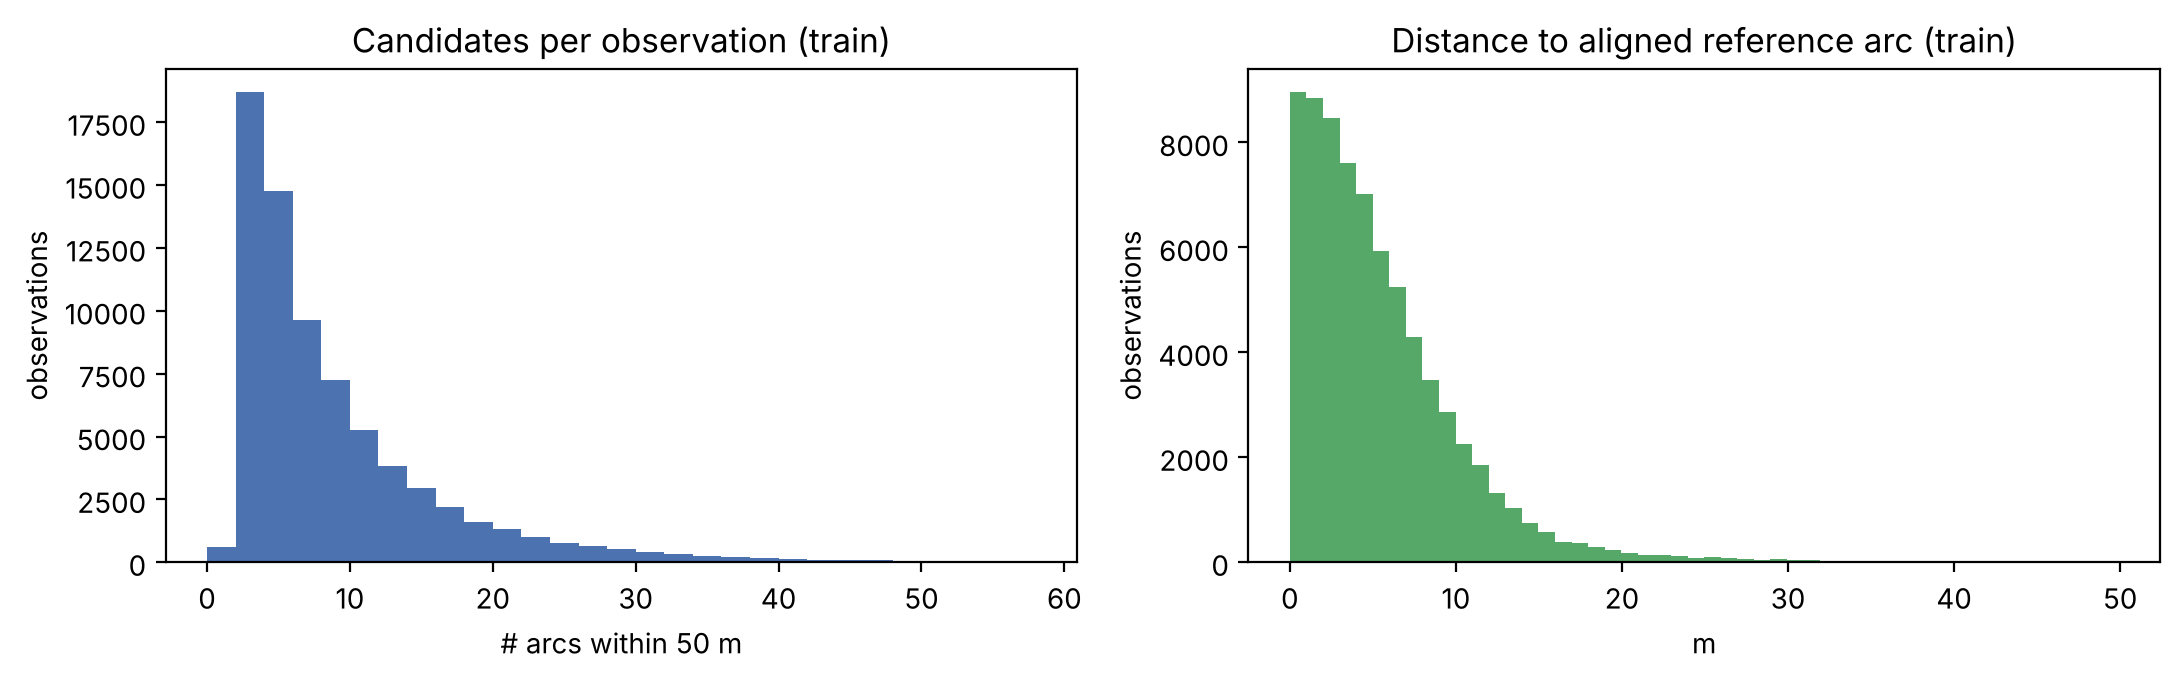

In [8]:
fig, ax = plt.subplots(1, 2, figsize=(11, 3.5))
lab_tr = points[(points.part == "train") & points.labelled]
ax[0].hist(lab_tr["n_cand"], bins=range(0, 60, 2), color="#4c72b0")
ax[0].set(title="Candidates per observation (train)", xlabel="# arcs within 50 m", ylabel="observations")
ax[1].hist(lab_tr["label_dist_m"], bins=50, color="#55a868")
ax[1].set(title="Distance to aligned reference arc (train)", xlabel="m", ylabel="observations")
plt.tight_layout(); plt.savefig(os.path.join(OUT_DIR, "candidates_hist.png"), dpi=120); plt.show()

## 4. Training data and evaluation helpers
- Training rows: candidates of **labelled** observations of train trips flagged `use_for_tuning`
  (76 of 80; the 4 excluded trips have large unlabelled stretches / poor reference coverage).
- CV: **5-fold GroupKFold by trip**, so no trip is split between fit and validation.
- Metrics
  - *Candidate-level* (binary: is this the true arc?): Macro F1, precision, recall, log loss.
  - *Observation-level Top-1 accuracy*: highest-probability candidate vs reference arc (missing candidates count as wrong).
  - *Observation-level Macro F1*: over arc IDs (`trip:arc`) of the Top-1 predictions.
  - *Route continuity*: share of consecutive observations (same segment) whose predicted arcs are equal
    or connected within ≤2 arcs in the directed network.

In [9]:
train_c = cands[(cands.part == "train") & cands.use_for_tuning & cands.labelled_pt].reset_index(drop=True)
test_c = cands[cands.part == "student_test"].reset_index(drop=True)
print("train rows", len(train_c), "| test rows", len(test_c), "| train trips", train_c.trip.nunique())

_net_cache = {}
def succ_nodes(part, tid):
    """For each node, the set of nodes reachable in one canonical arc (for continuity)."""
    if (part, tid) not in _net_cache:
        net = np.load(os.path.join(DATA_DIR, part, tid, "network_clean.npz"))
        c = net["arc_is_canonical"]
        u, v = net["arc_u"], net["arc_v"]
        s = pd.Series(v[c]).groupby(u[c]).apply(set).to_dict()
        _net_cache[(part, tid)] = (u, v, s)
    return _net_cache[(part, tid)]

def top1(c, prob):
    c = c[["trip", "part", "pt", "arc", "dist_m"]].copy(); c["prob"] = prob
    c = c.sort_values(["trip", "pt", "prob", "dist_m"], ascending=[True, True, False, True])
    return c.drop_duplicates(["trip", "pt"]).set_index(["trip", "pt"])["arc"]

def continuity(pts_df, pred_col):
    ok = tot = 0
    for (part, tid), g in pts_df.groupby(["part", "trip"]):
        u, v, s = succ_nodes(part, tid)
        g = g.sort_values("pt")
        a = g[pred_col].values; sg = g["seg"].values
        for i in range(1, len(a)):
            if sg[i] != sg[i - 1] or a[i] < 0 or a[i - 1] < 0:
                continue
            tot += 1
            p, q = a[i - 1], a[i]
            if p == q or v[p] == u[q] or u[q] in s.get(v[p], ()):
                ok += 1
    return ok / max(tot, 1)

def evaluate(model, c, pts_df, with_continuity=True):
    t = time.time(); prob = model.predict_proba(c[FEATURES])[:, 1]; infer_s = time.time() - t
    lab_mask = c["labelled_pt"].values
    y, p = c["label"].values[lab_mask], prob[lab_mask]
    yhat = (p >= 0.5).astype(int)
    pred = top1(c, prob)
    P = pts_df.set_index(["trip", "pt"]).copy()
    P["pred_arc"] = pred.reindex(P.index).fillna(-1).astype(int).values
    L = P[P.labelled]
    res = {
        "cand_macro_f1": f1_score(y, yhat, average="macro"),
        "cand_precision_pos": precision_score(y, yhat, zero_division=0),
        "cand_recall_pos": recall_score(y, yhat, zero_division=0),
        "cand_log_loss": log_loss(y, np.clip(p, 1e-15, 1 - 1e-15), labels=[0, 1]),
        "obs_top1_acc": float((L.pred_arc == L.true_arc).mean()),
        "obs_macro_f1": f1_score(L.index.get_level_values(0) + ":" + L.true_arc.astype(str),
                                 L.index.get_level_values(0) + ":" + L.pred_arc.astype(str), average="macro"),
        "cand_miss_rate": float(1 - L.true_in_cands.mean()),
        "infer_ms_per_obs": 1000 * infer_s / max(len(P), 1),
    }
    if with_continuity:
        res["route_continuity"] = continuity(P.reset_index(), "pred_arc")
    return res, prob, P

train rows 578536 | test rows 73903 | train trips 76


## 5. Decision Tree — cross-validation
**Why a decision tree?** The features interact non-linearly (e.g. *small distance* only matters if
*heading agrees*; heading only matters if *speed* is non-zero). A tree learns such if-then rules
directly, needs no feature scaling, and is fully interpretable. Its weaknesses: high variance,
piece-wise constant (poorly calibrated) probabilities, and a fully grown tree memorises the training data.

**Objective**: Gini impurity at each split (CART). We compare:
- *DT-default*: sklearn defaults (fully grown, `min_samples_leaf=1`).
- *Depth sweep*: `max_depth ∈ {2,…,20}` with `min_samples_leaf=20`, chosen by **mean CV candidate Macro F1**.

In [10]:
gkf = GroupKFold(n_splits=5)
folds = list(gkf.split(train_c, train_c["label"], groups=train_c["trip"]))
train_pts = points[(points.part == "train") & points.use_for_tuning]

def cv_run(make_model, name, cont=False):
    rows = []
    for k, (tr_i, va_i) in enumerate(folds):
        m = make_model()
        t = time.time(); m.fit(train_c.loc[tr_i, FEATURES], train_c.loc[tr_i, "label"]); fit_s = time.time() - t
        ctr, cva = train_c.loc[tr_i], train_c.loc[va_i]
        rtr, _, _ = evaluate(m, ctr, train_pts[train_pts.trip.isin(ctr.trip.unique())], with_continuity=False)
        rva, _, _ = evaluate(m, cva, train_pts[train_pts.trip.isin(cva.trip.unique())], with_continuity=cont)
        row = {"model": name, "fold": k, "fit_s": fit_s, "depth": m.get_depth(), "leaves": m.get_n_leaves()}
        row.update({f"train_{a}": b for a, b in rtr.items()}); row.update({f"val_{a}": b for a, b in rva.items()})
        rows.append(row)
    return pd.DataFrame(rows)

cv_default = cv_run(lambda: DecisionTreeClassifier(random_state=SEED), "DT-default", cont=True)
cv_default[["fold", "depth", "leaves", "train_cand_macro_f1", "val_cand_macro_f1", "val_obs_top1_acc",
            "val_cand_log_loss", "val_route_continuity", "fit_s"]].round(4)

,fold,depth,leaves,train_cand_macro_f1,val_cand_macro_f1,val_obs_top1_acc,val_cand_log_loss,val_route_continuity,fit_s
0,0,45,3866,1.0,0.9842,0.9773,0.2778,0.9772,7.7991
1,1,39,3692,1.0,0.9731,0.9579,0.3958,0.9578,7.7716
2,2,35,3413,1.0,0.9671,0.9446,0.4530,0.9430,7.9996
3,3,49,3353,1.0,0.9550,0.9217,0.5451,0.9042,7.1968
4,4,42,3293,1.0,0.9607,0.9409,0.5787,0.9265,8.4003


In [11]:
DEPTHS = [2, 3, 4, 6, 8, 10, 12, 15, 20]
sweep = pd.concat([cv_run(lambda d=d: DecisionTreeClassifier(max_depth=d, min_samples_leaf=20,
                                                           random_state=SEED), f"depth={d}")
                   .assign(max_depth=d) for d in DEPTHS], ignore_index=True)
sweep_s = sweep.groupby("max_depth").agg(
    train_f1=("train_cand_macro_f1", "mean"), val_f1=("val_cand_macro_f1", "mean"),
    val_f1_std=("val_cand_macro_f1", "std"), val_top1=("val_obs_top1_acc", "mean"),
    val_logloss=("val_cand_log_loss", "mean"), leaves=("leaves", "mean")).round(4)
sweep.to_csv(os.path.join(OUT_DIR, "dt_depth_sweep_folds.csv"), index=False)
sweep_s

,train_f1,val_f1,val_f1_std,val_top1,val_logloss,leaves
max_depth,,,,,,
2,0.9643,0.9620,0.0197,0.9451,0.0652,4.0
3,0.9651,0.9627,0.0197,0.9610,0.0494,8.0
4,0.9744,0.9733,0.0097,0.9688,0.0366,15.8
6,0.9790,0.9775,0.0088,0.9708,0.0299,54.2
8,0.9804,0.9780,0.0087,0.9715,0.0319,152.2
10,0.9817,0.9776,0.0094,0.9715,0.0384,320.0
12,0.9826,0.9771,0.0092,0.9715,0.0536,530.8
15,0.9833,0.9767,0.0095,0.9707,0.0776,820.8
20,0.9833,0.9768,0.0094,0.9702,0.1008,1059.6


Selected max_depth (best mean CV candidate Macro F1): 8


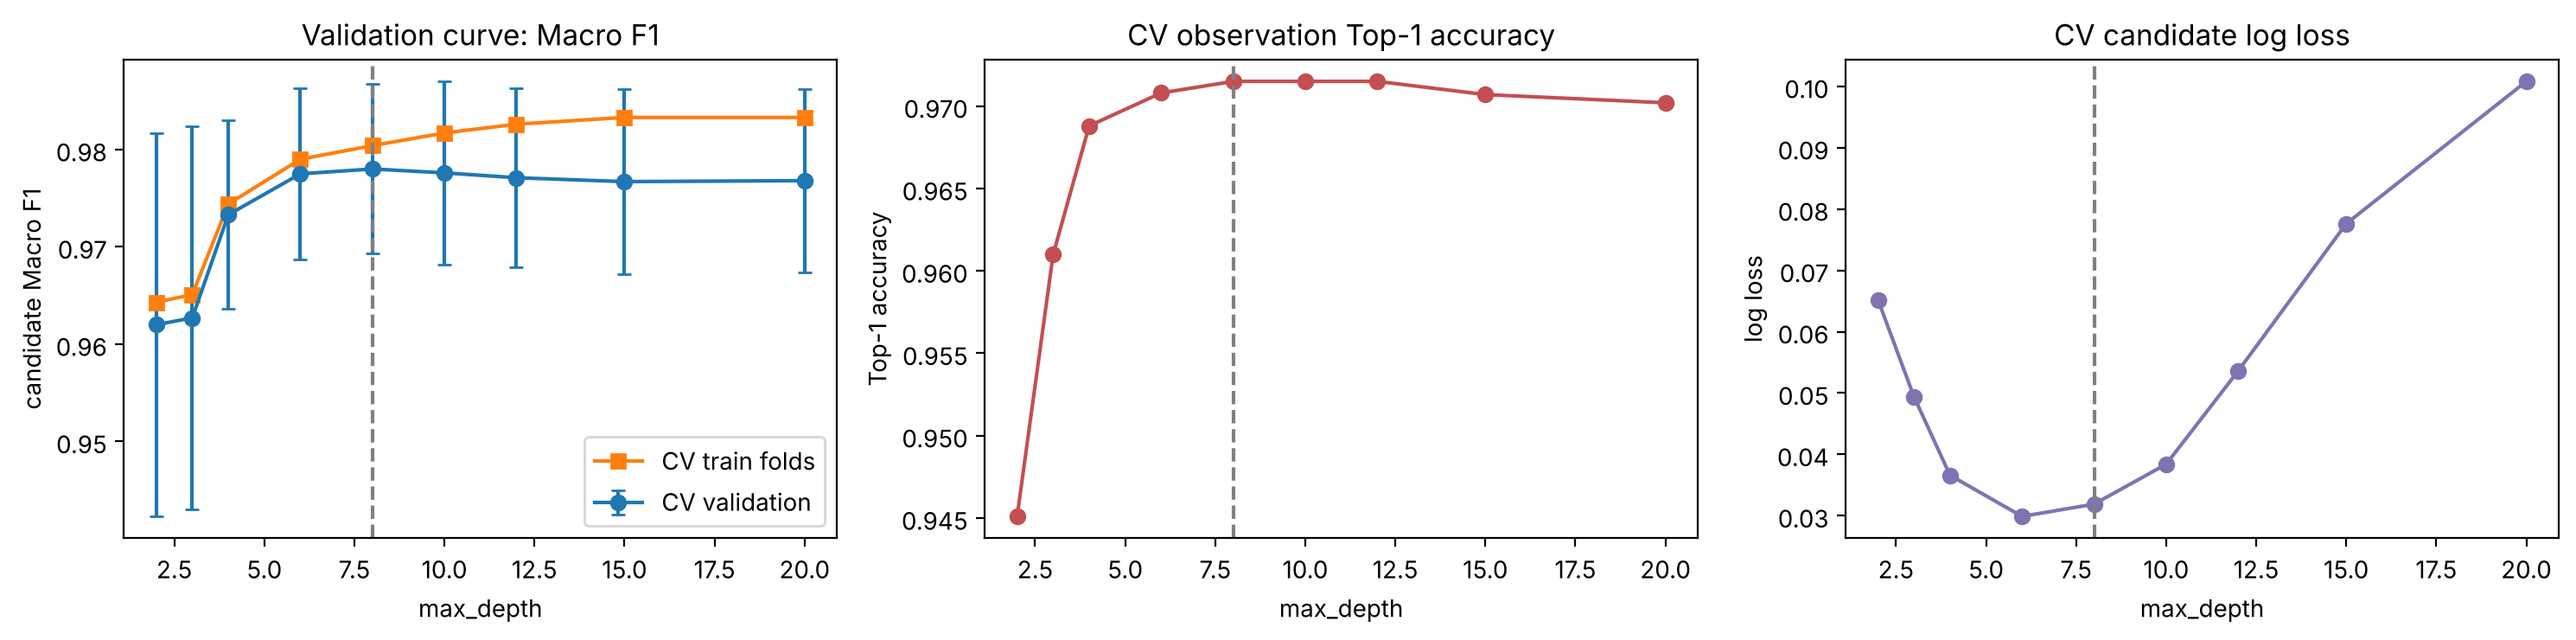

In [12]:
BEST_DEPTH = int(sweep_s["val_f1"].idxmax())
print("Selected max_depth (best mean CV candidate Macro F1):", BEST_DEPTH)
fig, ax = plt.subplots(1, 3, figsize=(15, 3.8))
ax[0].errorbar(sweep_s.index, sweep_s.val_f1, yerr=sweep_s.val_f1_std, marker="o", label="CV validation", capsize=3)
ax[0].plot(sweep_s.index, sweep_s.train_f1, marker="s", label="CV train folds")
ax[0].axvline(BEST_DEPTH, ls="--", c="gray"); ax[0].set(xlabel="max_depth", ylabel="candidate Macro F1", title="Validation curve: Macro F1"); ax[0].legend()
ax[1].plot(sweep_s.index, sweep_s.val_top1, marker="o", c="#c44e52"); ax[1].axvline(BEST_DEPTH, ls="--", c="gray")
ax[1].set(xlabel="max_depth", ylabel="Top-1 accuracy", title="CV observation Top-1 accuracy")
ax[2].plot(sweep_s.index, sweep_s.val_logloss, marker="o", c="#8172b2"); ax[2].axvline(BEST_DEPTH, ls="--", c="gray")
ax[2].set(xlabel="max_depth", ylabel="log loss", title="CV candidate log loss")
plt.tight_layout(); plt.savefig(os.path.join(OUT_DIR, "dt_validation_curve.png"), dpi=120); plt.show()

In [13]:
cv_best = cv_run(lambda: DecisionTreeClassifier(max_depth=BEST_DEPTH, min_samples_leaf=20, random_state=SEED),
                 f"DT-depth{BEST_DEPTH}", cont=True)
cv_all = pd.concat([cv_default, cv_best], ignore_index=True)
cv_all.to_csv(os.path.join(OUT_DIR, "dt_cv_folds.csv"), index=False)
cv_cmp = cv_all.groupby("model")[["train_cand_macro_f1", "val_cand_macro_f1", "val_obs_top1_acc", "val_obs_macro_f1",
                                   "val_cand_log_loss", "val_route_continuity", "fit_s"]].agg(["mean", "std"]).round(4)
cv_cmp

train_cand_macro_f1         val_cand_macro_f1          \
                          mean     std              mean     std   
model                                                              
DT-default              1.0000  0.0000             0.968  0.0113   
DT-depth8               0.9804  0.0025             0.978  0.0087   

           val_obs_top1_acc         val_obs_macro_f1          \
                       mean     std             mean     std   
model                                                          
DT-default           0.9485  0.0207           0.8463  0.0552   
DT-depth8            0.9715  0.0118           0.9164  0.0333   

           val_cand_log_loss         val_route_continuity           fit_s  \
                        mean     std                 mean     std    mean   
model                                                                       
DT-default            0.4501  0.1206               0.9418  0.0281  7.8335   
DT-depth8             0.0319  0.0104               0.9670  0.0129  4.6312   

                    
               std  
model               
DT-default  0.4357  
DT-depth8   0.2456

## 6. Refit on all 76 training trips → evaluate once on the 10 student-testing trips

In [14]:
final_models = {
    "DT-default": DecisionTreeClassifier(random_state=SEED),
    f"DT-depth{BEST_DEPTH}": DecisionTreeClassifier(max_depth=BEST_DEPTH, min_samples_leaf=20, random_state=SEED),
}
test_pts = points[points.part == "student_test"]
results, test_preds = {}, {}
for name, m in final_models.items():
    t = time.time(); m.fit(train_c[FEATURES], train_c["label"]); fit_s = time.time() - t
    r, prob, P = evaluate(m, test_c, test_pts)
    r.update({"train_time_s": fit_s, "depth": m.get_depth(), "leaves": m.get_n_leaves(),
              "cv_cand_macro_f1_mean": cv_all[cv_all.model == name].val_cand_macro_f1.mean(),
              "cv_cand_macro_f1_std": cv_all[cv_all.model == name].val_cand_macro_f1.std(),
              "cv_obs_top1_mean": cv_all[cv_all.model == name].val_obs_top1_acc.mean()})
    results[name] = r; test_preds[name] = (prob, P)

# reference: continuity of the reference labels themselves (upper bound for this metric)
gt = test_pts.copy(); gt["arc_lab"] = np.where(gt.labelled, gt.true_arc, -1)
ref_cont = continuity(gt, "arc_lab")
res_df = pd.DataFrame(results).T
res_df.to_csv(os.path.join(OUT_DIR, "dt_student_test_results.csv"))
print(f"Route continuity of the reference labels on student-test: {ref_cont:.4f}")
res_df[["cv_cand_macro_f1_mean", "cv_cand_macro_f1_std", "cv_obs_top1_mean", "obs_top1_acc", "obs_macro_f1",
        "cand_macro_f1", "cand_precision_pos", "cand_recall_pos", "cand_log_loss", "route_continuity",
        "cand_miss_rate", "train_time_s", "infer_ms_per_obs", "depth", "leaves"]].T.round(4)

Route continuity of the reference labels on student-test: 0.9814


,DT-default,DT-depth8
cv_cand_macro_f1_mean,0.9680,0.9780
cv_cand_macro_f1_std,0.0113,0.0087
cv_obs_top1_mean,0.9485,0.9715
obs_top1_acc,0.9477,0.9690
obs_macro_f1,0.8303,0.9070
cand_macro_f1,0.9652,0.9764
cand_precision_pos,0.9325,0.9407
cand_recall_pos,0.9445,0.9765
cand_log_loss,0.4936,0.0304
route_continuity,0.9471,0.9635


### Per-trip Top-1 accuracy on student-test (selected model)

In [15]:
SEL = f"DT-depth{BEST_DEPTH}"
prob_sel, P_sel = test_preds[SEL]
L = P_sel[P_sel.labelled].reset_index()
per_trip = L.groupby("trip").apply(lambda g: pd.Series({
    "labelled_obs": len(g), "top1_acc": (g.pred_arc == g.true_arc).mean(),
    "cand_miss_rate": 1 - g.true_in_cands.mean(), "mean_candidates": g.n_cand.mean()})).round(4)
per_trip.to_csv(os.path.join(OUT_DIR, "dt_student_test_per_trip.csv"))
per_trip

,labelled_obs,top1_acc,cand_miss_rate,mean_candidates
trip,,,,
00000000,1713.0,0.9901,0.0,3.8891
00000007,724.0,0.9959,0.0,3.7376
00000009,425.0,0.9247,0.0,18.6165
00000040,1570.0,0.9854,0.0,4.6191
00000052,176.0,0.9602,0.0,8.8920
00000056,2165.0,0.9409,0.0,10.6342
00000065,275.0,0.9564,0.0,14.3891
00000076,527.0,0.9526,0.0,19.0702
00000077,624.0,0.9920,0.0,10.3926


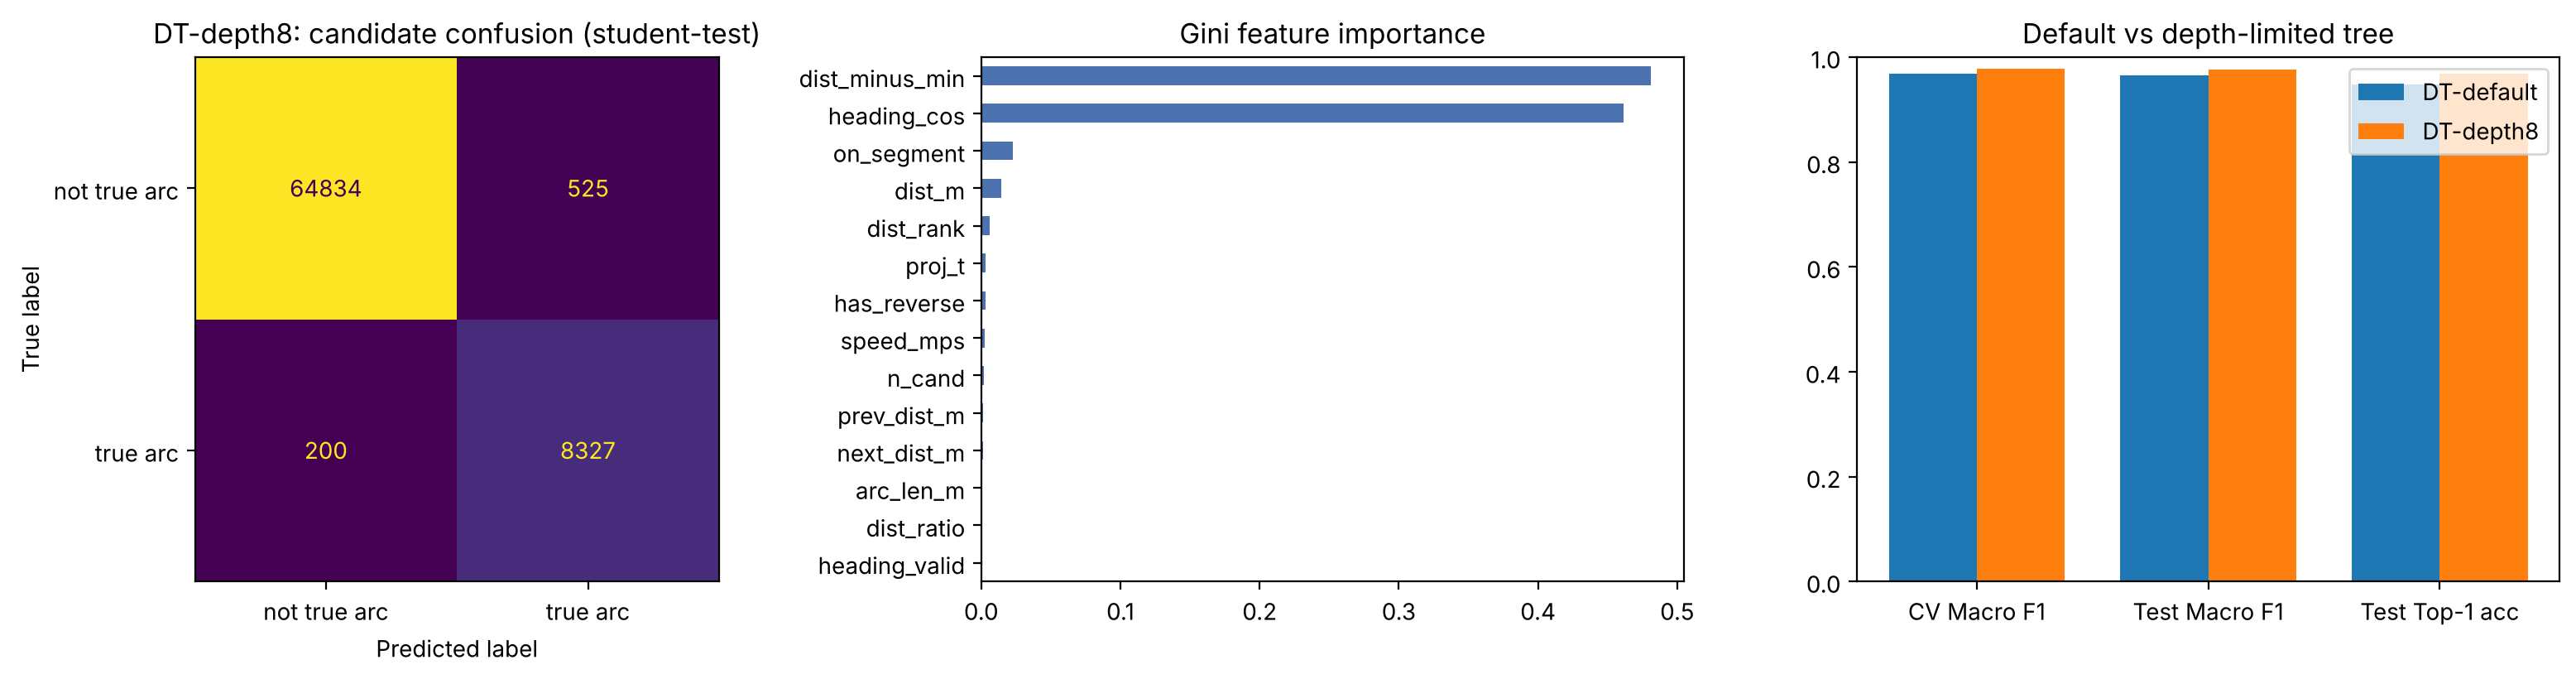

In [16]:
fig, ax = plt.subplots(1, 3, figsize=(16, 4.2))
mask = test_c["labelled_pt"].values
ConfusionMatrixDisplay(confusion_matrix(test_c["label"].values[mask], (prob_sel[mask] >= 0.5).astype(int)),
                       display_labels=["not true arc", "true arc"]).plot(ax=ax[0], colorbar=False, values_format="d")
ax[0].set_title(f"{SEL}: candidate confusion (student-test)")
imp = pd.Series(final_models[SEL].feature_importances_, index=FEATURES).sort_values()
imp.plot.barh(ax=ax[1], color="#4c72b0"); ax[1].set_title("Gini feature importance")
names = list(results)
x = np.arange(3); w = 0.38
for k, n in enumerate(names):
    vals = [results[n]["cv_cand_macro_f1_mean"], results[n]["cand_macro_f1"], results[n]["obs_top1_acc"]]
    ax[2].bar(x + (k - 0.5) * w, vals, w, label=n)
ax[2].set_xticks(x, ["CV Macro F1", "Test Macro F1", "Test Top-1 acc"]); ax[2].set_ylim(0, 1); ax[2].legend()
ax[2].set_title("Default vs depth-limited tree")
plt.tight_layout(); plt.savefig(os.path.join(OUT_DIR, "dt_test_diagnostics.png"), dpi=120); plt.show()

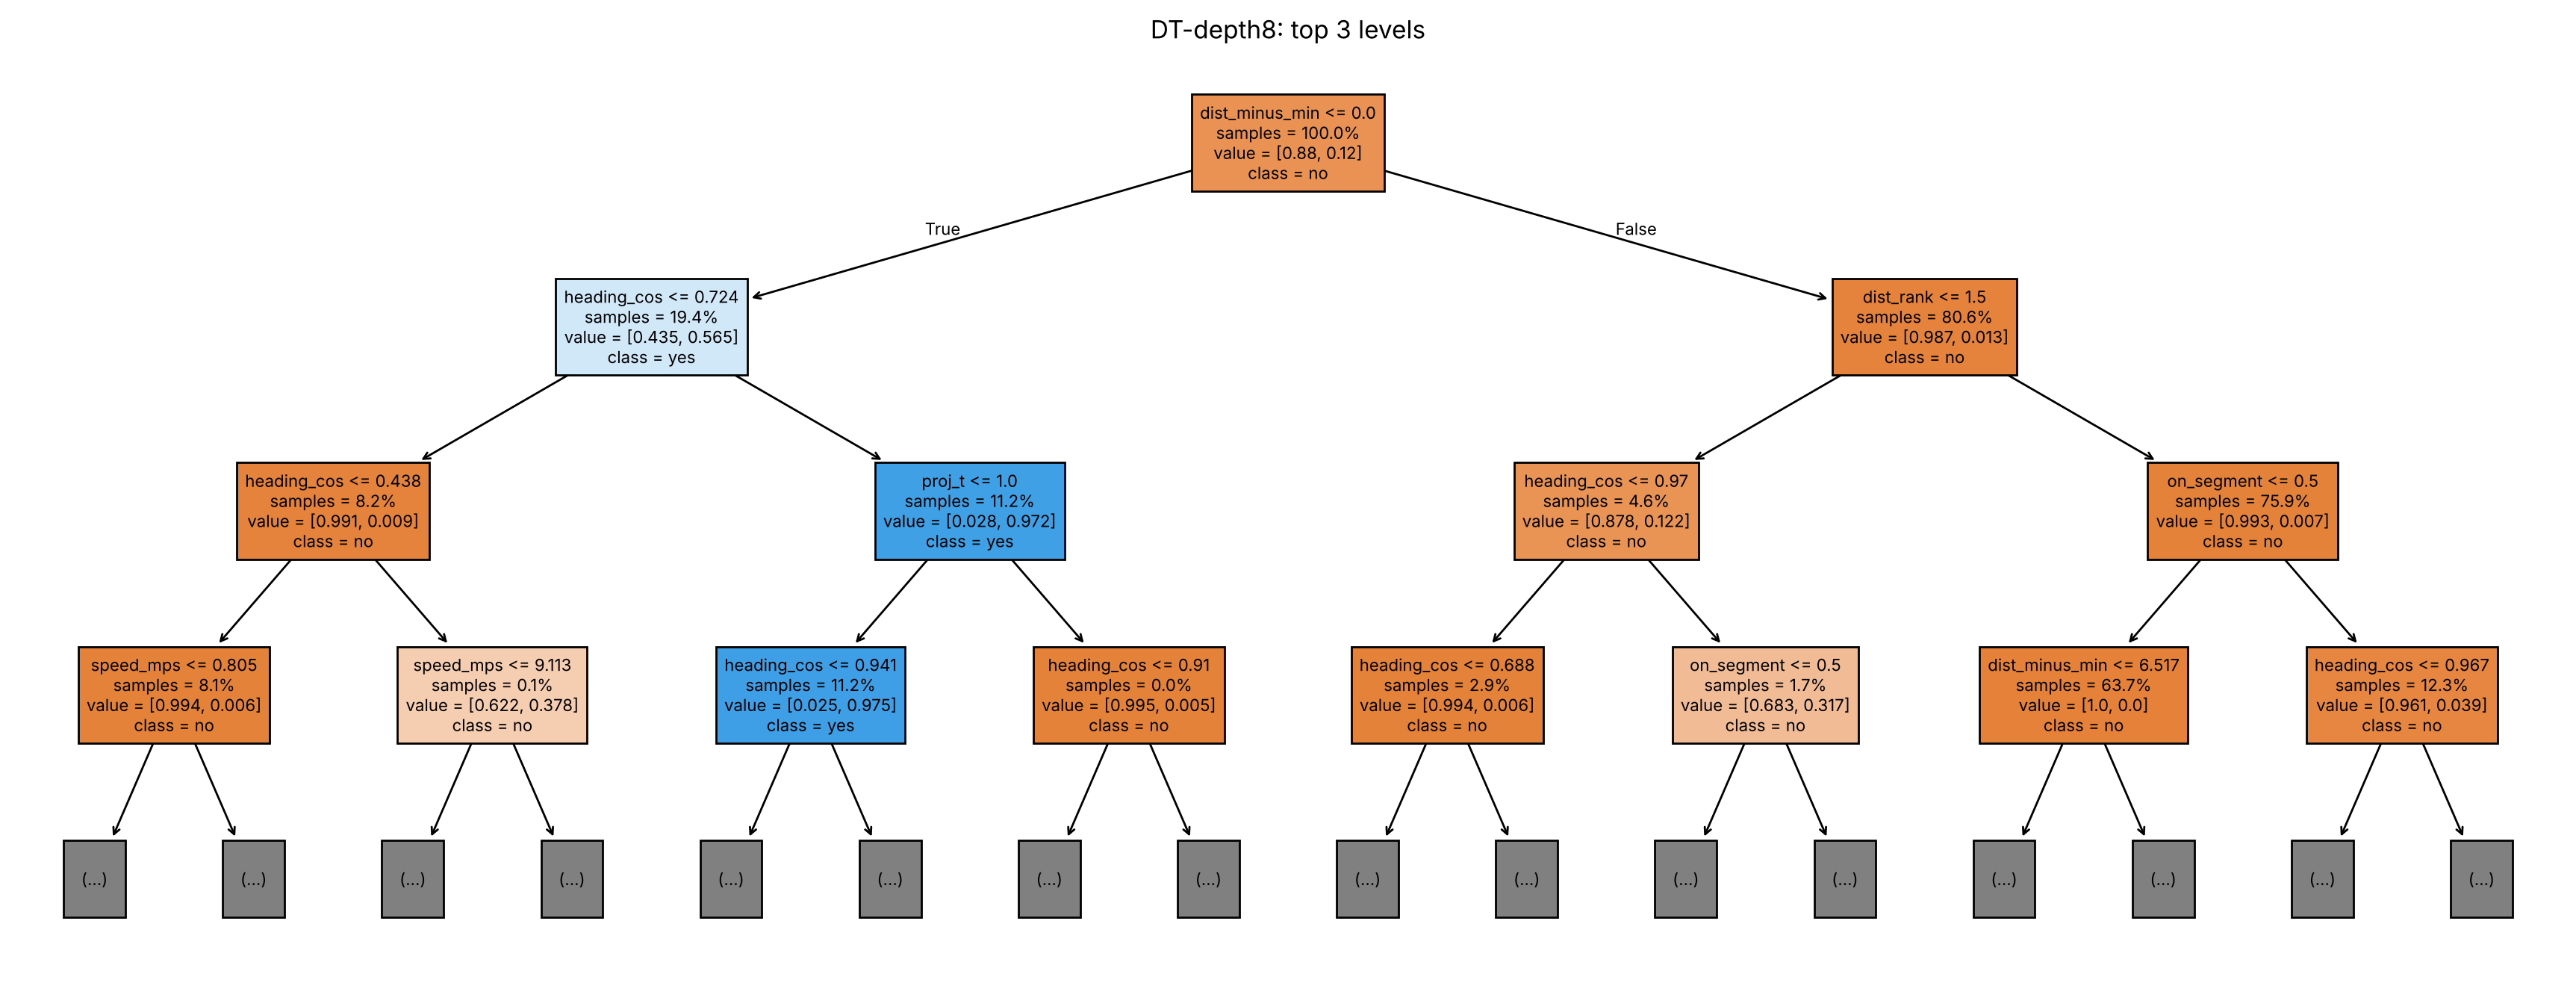

In [17]:
plt.figure(figsize=(22, 8))
plot_tree(final_models[SEL], max_depth=3, feature_names=FEATURES, class_names=["no", "yes"],
          filled=True, impurity=False, proportion=True, fontsize=8)
plt.title(f"{SEL}: top 3 levels"); plt.savefig(os.path.join(OUT_DIR, "dt_tree_top3.png"), dpi=110, bbox_inches="tight"); plt.show()

## 7. Folium map — classifier-only prediction on one student-test trip
Layers: raw (smoothed) GPS observations, nearby road network, reference route, predicted arcs
(correct = red, wrong = orange markers).

In [18]:
import folium
def trip_map(tid, part="student_test"):
    net, tr, route, qc = load_trip(part, tid)
    nlon, nlat, u, v = net["node_lon"], net["node_lat"], net["arc_u"], net["arc_v"]
    P = P_sel.loc[tid].reset_index()
    cand_arcs = test_c[test_c.trip == tid].arc.unique()
    m = folium.Map(location=[P.lat.mean(), P.lon.mean()], zoom_start=14, tiles="cartodbpositron")
    fg_net = folium.FeatureGroup("Road network (candidate arcs)", show=True)
    for a in cand_arcs:
        folium.PolyLine([(nlat[u[a]], nlon[u[a]]), (nlat[v[a]], nlon[v[a]])], color="#999", weight=1, opacity=0.6).add_to(fg_net)
    fg_ref = folium.FeatureGroup("Reference route", show=True)
    for a in route.canonical_arc_id:
        folium.PolyLine([(nlat[u[a]], nlon[u[a]]), (nlat[v[a]], nlon[v[a]])], color="green", weight=6, opacity=0.5).add_to(fg_ref)
    fg_pred = folium.FeatureGroup("Predicted arcs (DT top-1)", show=True)
    for a in P.pred_arc[P.pred_arc >= 0].unique():
        folium.PolyLine([(nlat[u[a]], nlon[u[a]]), (nlat[v[a]], nlon[v[a]])], color="red", weight=3).add_to(fg_pred)
    fg_gps = folium.FeatureGroup("GPS observations", show=True)
    fg_err = folium.FeatureGroup("Wrong top-1 observations", show=True)
    for r in P.itertuples():
        folium.CircleMarker((r.lat, r.lon), radius=2, color="blue", fill=True, opacity=0.7).add_to(fg_gps)
        if r.labelled and r.pred_arc != r.true_arc:
            folium.CircleMarker((r.lat, r.lon), radius=5, color="orange", fill=False, weight=2,
                                tooltip=f"pt {r.pt}: pred {r.pred_arc} / ref {r.true_arc}").add_to(fg_err)
    for fg in [fg_net, fg_ref, fg_pred, fg_gps, fg_err]: fg.add_to(m)
    folium.LayerControl(collapsed=False).add_to(m)
    acc = per_trip.loc[tid, "top1_acc"]
    m.get_root().html.add_child(folium.Element(
        f"<div style='position:fixed;top:10px;left:50px;z-index:999;background:white;padding:6px;border:1px solid #888;font-size:13px'>"
        f"<b>Trip {tid}</b> — {SEL} classifier-only, Top-1 acc {acc:.3f}<br>"
        f"<span style='color:blue'>●</span> GPS &nbsp;<span style='color:green'>━</span> reference &nbsp;"
        f"<span style='color:red'>━</span> predicted &nbsp;<span style='color:orange'>○</span> wrong</div>"))
    m.fit_bounds([[P.lat.min(), P.lon.min()], [P.lat.max(), P.lon.max()]])
    return m

MAP_TRIP = per_trip["labelled_obs"].sort_values().index[len(per_trip) // 2]   # a mid-sized test trip
fmap = trip_map(MAP_TRIP)
fmap.save(os.path.join(OUT_DIR, f"dt_map_trip_{MAP_TRIP}.html"))
print("saved", os.path.join(OUT_DIR, f"dt_map_trip_{MAP_TRIP}.html"))
fmap

saved outputs/decision_tree/dt_map_trip_00000077.html


## 8. Save model and results

In [19]:
joblib.dump({"model": final_models[SEL], "features": FEATURES, "cand_radius_m": CAND_RADIUS_M,
             "max_depth": BEST_DEPTH, "seed": SEED}, os.path.join(OUT_DIR, "decision_tree.joblib"))
summary = {"selected": SEL, "best_max_depth": BEST_DEPTH, "features": FEATURES,
           "reference_route_continuity_student_test": ref_cont,
           "results": {k: {a: float(b) for a, b in v.items()} for k, v in results.items()}}
json.dump(summary, open(os.path.join(OUT_DIR, "dt_results.json"), "w"), indent=2)
P_sel.reset_index().to_csv(os.path.join(OUT_DIR, "dt_student_test_predictions.csv"), index=False)
print(json.dumps(summary["results"][SEL], indent=2))

{
  "cand_macro_f1": 0.9763614353943586,
  "cand_precision_pos": 0.9406913691821057,
  "cand_recall_pos": 0.9765450920605137,
  "cand_log_loss": 0.030364725157343304,
  "obs_top1_acc": 0.969039521519878,
  "obs_macro_f1": 0.9070127216135613,
  "cand_miss_rate": 0.0,
  "infer_ms_per_obs": 0.0008631115708353929,
  "route_continuity": 0.9635147817925857,
  "train_time_s": 5.7961061000823975,
  "depth": 8.0,
  "leaves": 163.0,
  "cv_cand_macro_f1_mean": 0.9780159888824853,
  "cv_cand_macro_f1_std": 0.008706512237724263,
  "cv_obs_top1_mean": 0.971516504265918
}


## 9. Final results — Decision Tree (selected: depth 8)
This section is self-contained: it reads only the files saved above (`outputs/decision_tree/`) and the
cleaned data, so it can be re-run on its own.

In [1]:
import os, json, numpy as np, pandas as pd, matplotlib.pyplot as plt, folium
from scipy.spatial import cKDTree
from sklearn.metrics import f1_score
DATA_DIR = DATA_DIR if "DATA_DIR" in globals() else "data_clean"
OUT_DIR = "outputs/decision_tree"
MAP_DIR = os.path.join(OUT_DIR, "maps"); os.makedirs(MAP_DIR, exist_ok=True)
R = json.load(open(os.path.join(OUT_DIR, "dt_results.json")))
SEL = R["selected"]; res = R["results"][SEL]; base = R["results"]["DT-default"]
pred = pd.read_csv(os.path.join(OUT_DIR, "dt_student_test_predictions.csv"), dtype={"trip": str})
print("Selected model:", SEL)

Selected model: DT-depth8


### 9.1 Final metrics (student-testing partition, 10 trips)

In [2]:
def load_net(tid):
    z = np.load(os.path.join(DATA_DIR, "student_test", tid, "network_clean.npz"))
    c = z["arc_is_canonical"]
    succ = pd.Series(z["arc_v"][c]).groupby(z["arc_u"][c]).apply(set).to_dict()
    return z, succ

def trip_continuity(g, z, succ):
    u, v = z["arc_u"], z["arc_v"]; a = g.pred_arc.values; s = g.seg.values; ok = tot = 0
    for i in range(1, len(a)):
        if s[i] != s[i-1] or a[i] < 0 or a[i-1] < 0: continue
        tot += 1; p, q = a[i-1], a[i]
        ok += (p == q) or (v[p] == u[q]) or (u[q] in succ.get(v[p], ()))
    return ok / max(tot, 1)

rows, NETS = [], {}
for tid, g in pred.groupby("trip"):
    g = g.sort_values("pt"); z, succ = load_net(tid); NETS[tid] = z
    L = g[g.labelled]
    rows.append({"trip": tid, "observations": len(g), "labelled_obs": len(L),
                 "mean_candidates": round(g.n_cand.mean(), 2),
                 "top1_accuracy": (L.pred_arc == L.true_arc).mean(),
                 "obs_macro_f1": f1_score(L.true_arc, L.pred_arc, average="macro"),
                 "wrong_obs": int((L.pred_arc != L.true_arc).sum()),
                 "route_continuity": trip_continuity(g, z, succ)})
per_trip = pd.DataFrame(rows).set_index("trip")
overall = {"observations": per_trip.observations.sum(), "labelled_obs": per_trip.labelled_obs.sum(),
           "mean_candidates": round(pred.n_cand.mean(), 2), "top1_accuracy": res["obs_top1_acc"],
           "obs_macro_f1": res["obs_macro_f1"], "wrong_obs": per_trip.wrong_obs.sum(),
           "route_continuity": res["route_continuity"]}
per_trip.loc["ALL (pooled)"] = overall
per_trip.round(4).to_csv(os.path.join(OUT_DIR, "FINAL_per_trip_metrics.csv"))
per_trip.round(4)

,observations,labelled_obs,mean_candidates,top1_accuracy,obs_macro_f1,wrong_obs,route_continuity
trip,,,,,,,
00000000,1713,1713,3.89,0.9901,0.9048,17,0.9924
00000007,724,724,3.74,0.9959,0.9821,3,1.0000
00000009,425,425,18.62,0.9247,0.8719,32,0.9269
00000040,1570,1570,4.62,0.9854,0.9163,23,0.9853
00000052,176,176,8.89,0.9602,0.8460,7,0.9486
00000056,2173,2165,10.60,0.9409,0.9002,128,0.9222
00000065,275,275,14.39,0.9564,0.8946,12,0.9780
00000076,527,527,19.07,0.9526,0.8843,25,0.9278
00000077,624,624,10.39,0.9920,0.9820,5,0.9952


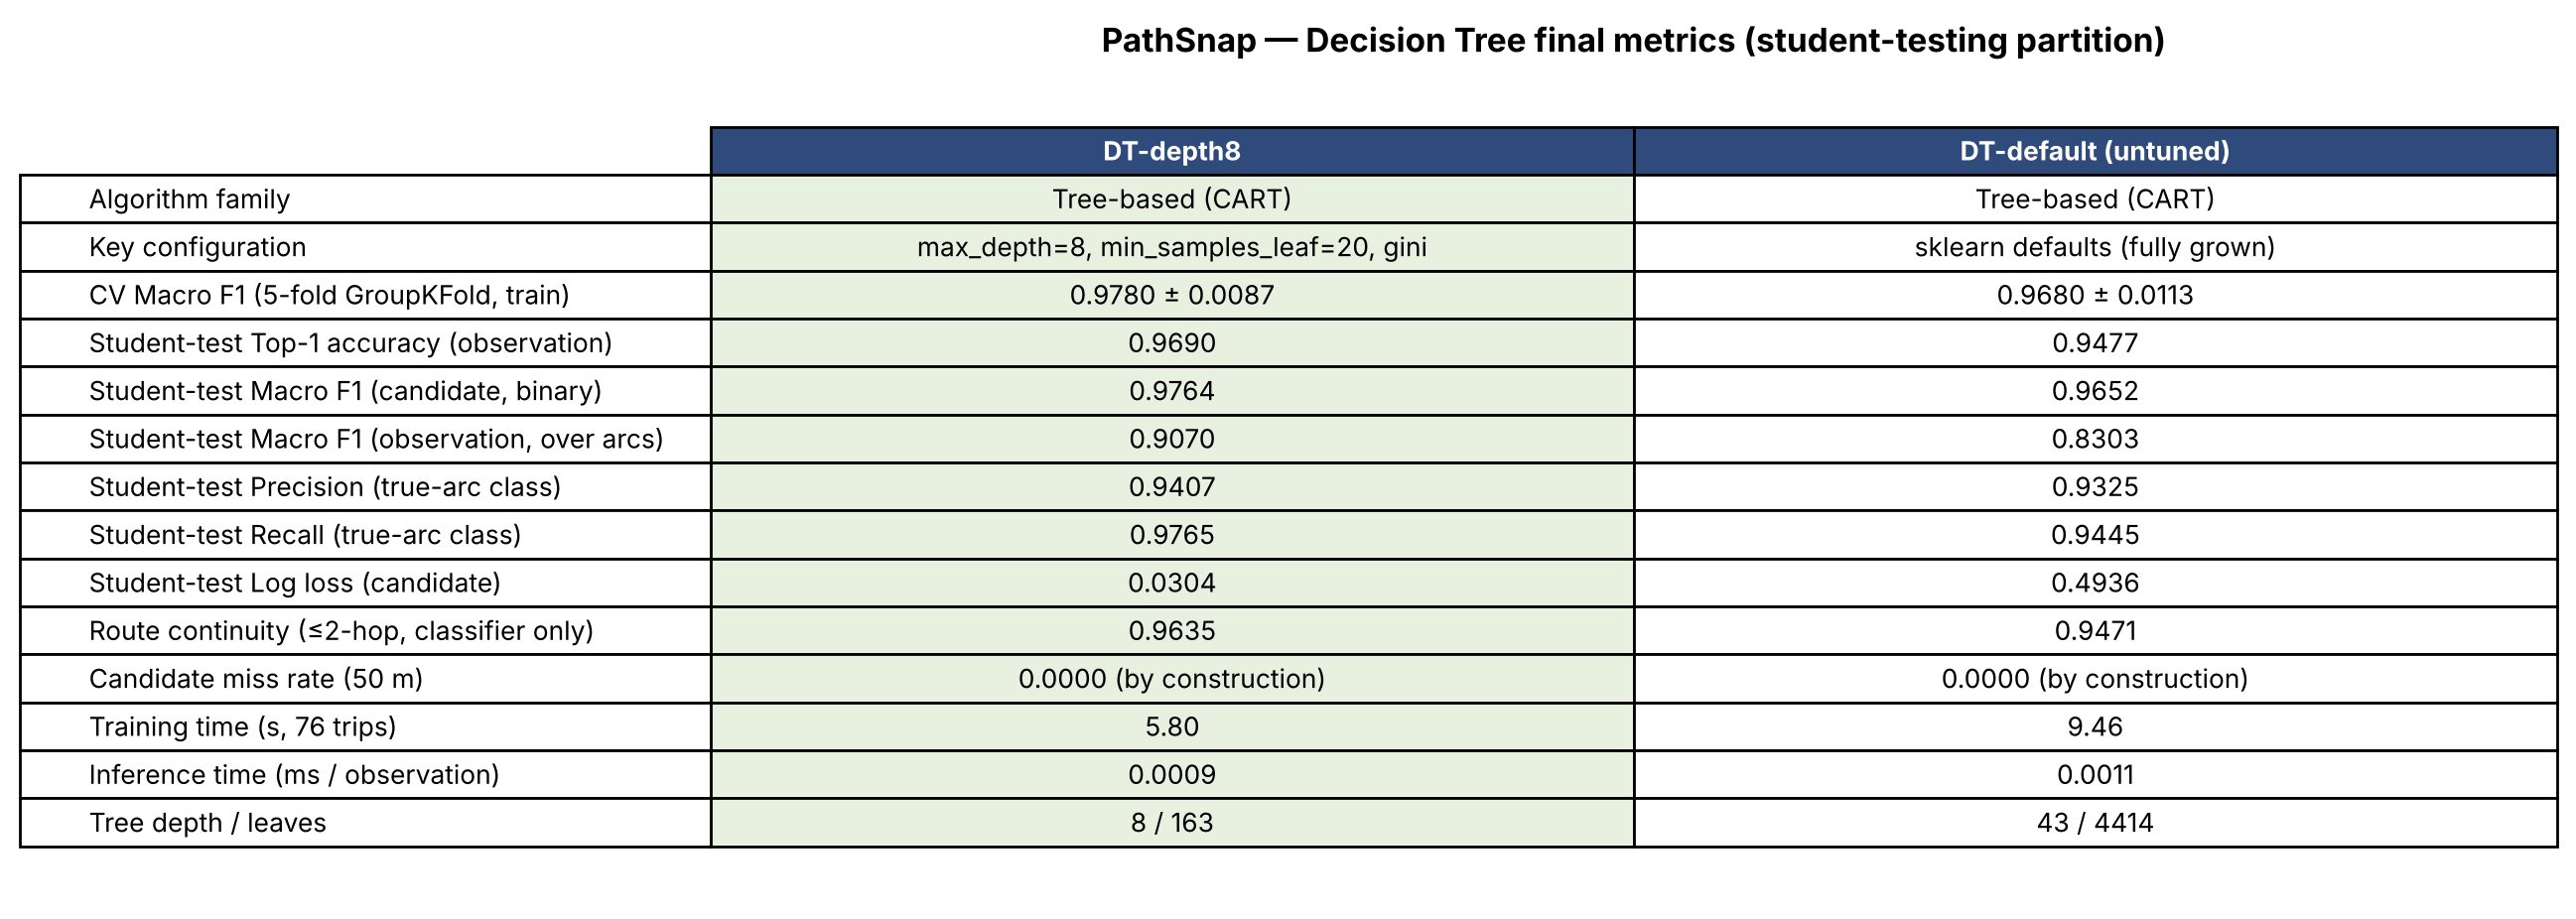

,DT-depth8,DT-default (untuned)
Metric,,
Algorithm family,Tree-based (CART),Tree-based (CART)
Key configuration,"max_depth=8, min_samples_leaf=20, gini",sklearn defaults (fully grown)
"CV Macro F1 (5-fold GroupKFold, train)",0.9780 ± 0.0087,0.9680 ± 0.0113
Student-test Top-1 accuracy (observation),0.9690,0.9477
"Student-test Macro F1 (candidate, binary)",0.9764,0.9652
"Student-test Macro F1 (observation, over arcs)",0.9070,0.8303
Student-test Precision (true-arc class),0.9407,0.9325
Student-test Recall (true-arc class),0.9765,0.9445
Student-test Log loss (candidate),0.0304,0.4936


In [3]:
final = pd.DataFrame({
    "Metric": ["Algorithm family", "Key configuration", "CV Macro F1 (5-fold GroupKFold, train)",
               "Student-test Top-1 accuracy (observation)", "Student-test Macro F1 (candidate, binary)",
               "Student-test Macro F1 (observation, over arcs)", "Student-test Precision (true-arc class)",
               "Student-test Recall (true-arc class)", "Student-test Log loss (candidate)",
               "Route continuity (≤2-hop, classifier only)", "Candidate miss rate (50 m)",
               "Training time (s, 76 trips)", "Inference time (ms / observation)", "Tree depth / leaves"],
    SEL: ["Tree-based (CART)", "max_depth=8, min_samples_leaf=20, gini",
          f"{res['cv_cand_macro_f1_mean']:.4f} ± {res['cv_cand_macro_f1_std']:.4f}",
          f"{res['obs_top1_acc']:.4f}", f"{res['cand_macro_f1']:.4f}", f"{res['obs_macro_f1']:.4f}",
          f"{res['cand_precision_pos']:.4f}", f"{res['cand_recall_pos']:.4f}", f"{res['cand_log_loss']:.4f}",
          f"{res['route_continuity']:.4f}", f"{res['cand_miss_rate']:.4f} (by construction)",
          f"{res['train_time_s']:.2f}", f"{res['infer_ms_per_obs']:.4f}",
          f"{int(res['depth'])} / {int(res['leaves'])}"],
    "DT-default (untuned)": ["Tree-based (CART)", "sklearn defaults (fully grown)",
          f"{base['cv_cand_macro_f1_mean']:.4f} ± {base['cv_cand_macro_f1_std']:.4f}",
          f"{base['obs_top1_acc']:.4f}", f"{base['cand_macro_f1']:.4f}", f"{base['obs_macro_f1']:.4f}",
          f"{base['cand_precision_pos']:.4f}", f"{base['cand_recall_pos']:.4f}", f"{base['cand_log_loss']:.4f}",
          f"{base['route_continuity']:.4f}", f"{base['cand_miss_rate']:.4f} (by construction)",
          f"{base['train_time_s']:.2f}", f"{base['infer_ms_per_obs']:.4f}",
          f"{int(base['depth'])} / {int(base['leaves'])}"],
}).set_index("Metric")
final.to_csv(os.path.join(OUT_DIR, "FINAL_metrics_table.csv"))

fig, ax = plt.subplots(figsize=(12, 5.4)); ax.axis("off")
tb = ax.table(cellText=final.values, rowLabels=final.index, colLabels=final.columns, loc="center", cellLoc="center")
tb.auto_set_font_size(False); tb.set_fontsize(9.5); tb.scale(1, 1.45)
for (r, c), cell in tb.get_celld().items():
    if r == 0: cell.set_facecolor("#2f4b7c"); cell.get_text().set_color("white"); cell.get_text().set_weight("bold")
    elif c == 0: cell.set_facecolor("#e8f0e0")
ax.set_title("PathSnap — Decision Tree final metrics (student-testing partition)", weight="bold", pad=8)
plt.savefig(os.path.join(OUT_DIR, "FINAL_metrics_table.png"), dpi=150, bbox_inches="tight"); plt.show()
final

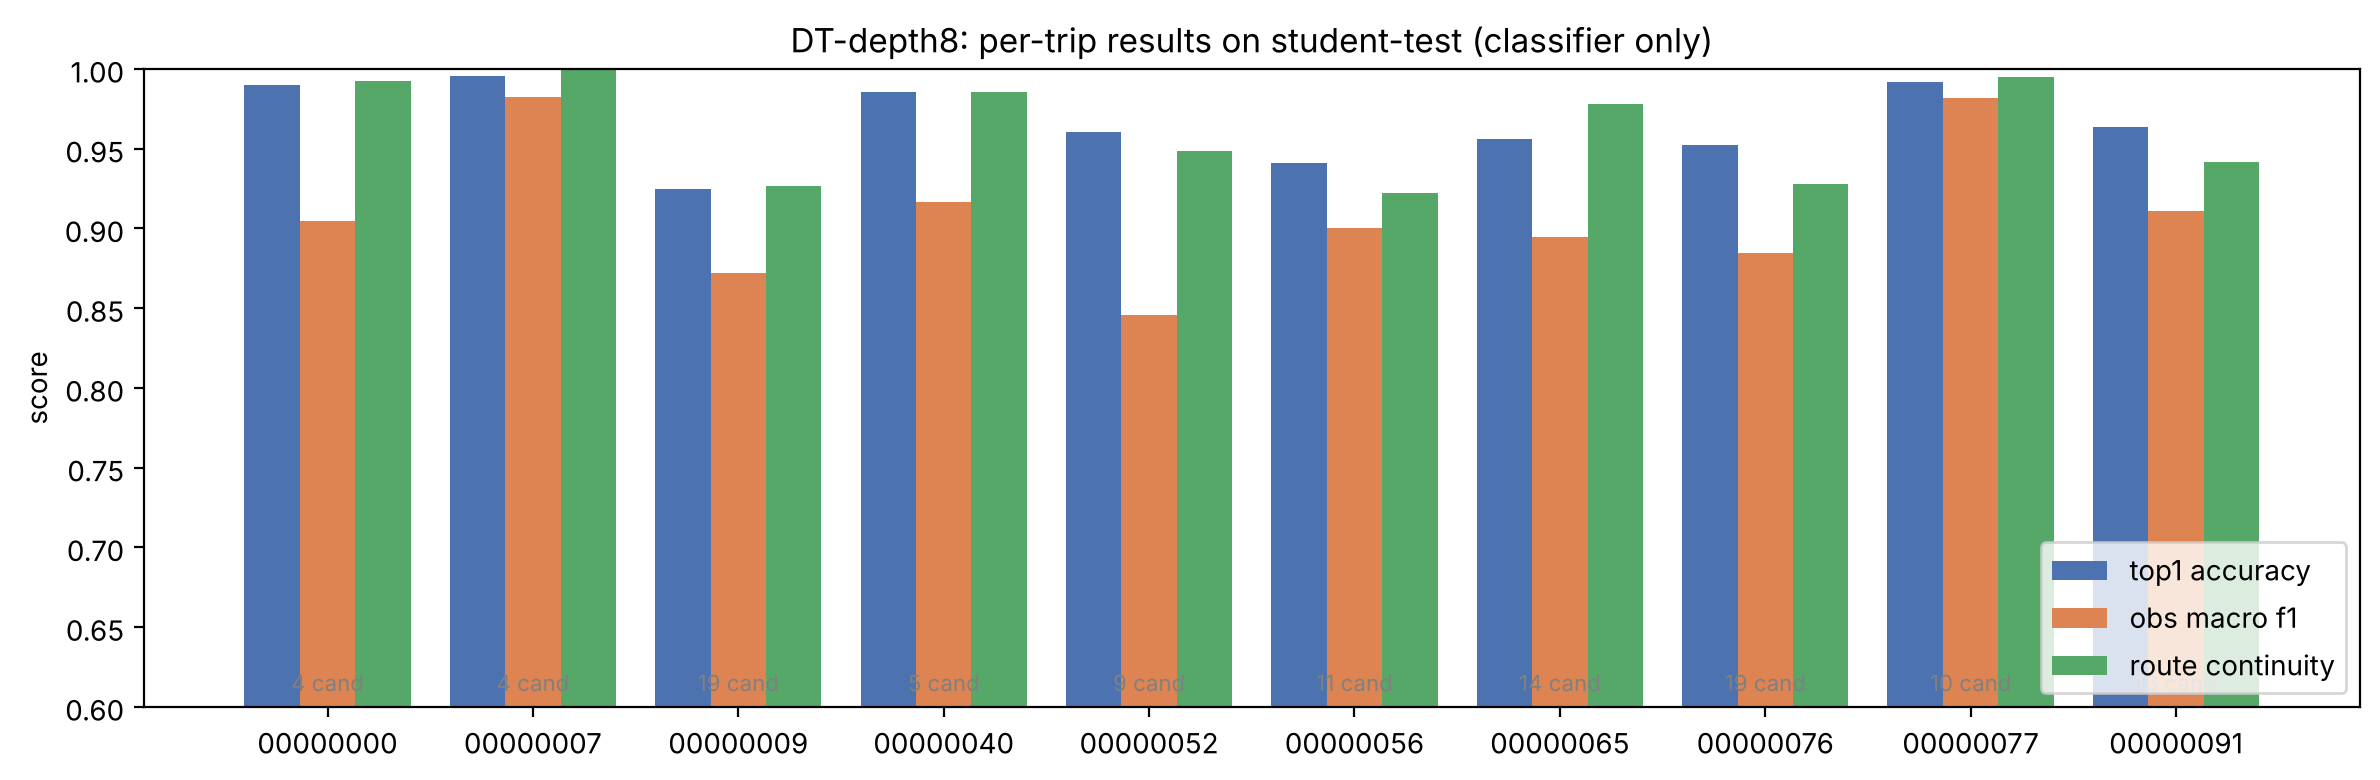

In [4]:
pt = per_trip.drop("ALL (pooled)")
fig, ax = plt.subplots(figsize=(12, 4))
x = np.arange(len(pt)); w = 0.27
for k, (col, c) in enumerate([("top1_accuracy", "#4c72b0"), ("obs_macro_f1", "#dd8452"), ("route_continuity", "#55a868")]):
    ax.bar(x + (k - 1) * w, pt[col], w, label=col.replace("_", " "), color=c)
ax.set_xticks(x, pt.index, rotation=0); ax.set_ylim(0.6, 1.0); ax.set_ylabel("score")
ax.set_title(f"{SEL}: per-trip results on student-test (classifier only)"); ax.legend(loc="lower right")
for i, n in enumerate(pt.mean_candidates): ax.text(i, 0.61, f"{n:.0f} cand", ha="center", fontsize=8, color="gray")
plt.tight_layout(); plt.savefig(os.path.join(OUT_DIR, "FINAL_per_trip_bars.png"), dpi=150); plt.show()

### 9.2 Folium maps — one interactive map per student-test trip
Layers (toggle top-right): raw GPS track, nearby road network, reference route (green),
predicted route (red, dashed), GPS observations coloured by correctness (green = correct arc,
red = wrong arc, grey = unlabelled), start/end markers. Click any point for its predicted and reference arc.

In [5]:
def arc_line(z, a):
    return [(z["node_lat"][z["arc_u"][a]], z["node_lon"][z["arc_u"][a]]),
            (z["node_lat"][z["arc_v"][a]], z["node_lon"][z["arc_v"][a]])]

def chain(z, arcs):
    """Merge consecutive connected arcs into polylines (breaks start a new polyline)."""
    lines, cur = [], []
    for a in arcs:
        seg = arc_line(z, a)
        if cur and cur[-1] == seg[0]: cur.append(seg[1])
        else:
            if cur: lines.append(cur)
            cur = list(seg)
    if cur: lines.append(cur)
    return lines

def nearby_arcs(z, g, radius_m=80):
    lat0 = np.radians(g.lat.mean()); k = 111320.0
    P = np.c_[g.lon.values * k * np.cos(lat0), g.lat.values * k]
    N = np.c_[z["node_lon"] * k * np.cos(lat0), z["node_lat"] * k]
    d, _ = cKDTree(P).query(N, distance_upper_bound=radius_m)
    near = np.isfinite(d)
    c = z["arc_is_canonical"]
    return np.where(c & (near[z["arc_u"]] | near[z["arc_v"]]))[0]

def make_map(tid):
    z = NETS[tid]; g = pred[pred.trip == tid].sort_values("pt")
    raw = pd.read_csv(os.path.join(DATA_DIR, "student_test", tid, "track_clean.csv"))
    route = pd.read_csv(os.path.join(DATA_DIR, "labels", "student_test", tid, "route_clean.csv"))
    m = folium.Map(tiles=None, control_scale=True)
    folium.TileLayer("openstreetmap", name="OpenStreetMap").add_to(m)

    fg = folium.FeatureGroup("Road network (within 80 m)", show=True)
    for a in nearby_arcs(z, g):
        folium.PolyLine(arc_line(z, a), color="#7f7f7f", weight=1, opacity=0.55).add_to(fg)
    fg.add_to(m)

    fg = folium.FeatureGroup("Raw GPS track (all points)", show=False)
    folium.PolyLine(list(zip(raw.lat, raw.lon)), color="#1f77b4", weight=1.5, opacity=0.7).add_to(fg)
    fg.add_to(m)

    fg = folium.FeatureGroup("Reference route", show=True)
    for line in chain(z, route.canonical_arc_id.values):
        folium.PolyLine(line, color="#2ca02c", weight=7, opacity=0.55, tooltip="reference route").add_to(fg)
    fg.add_to(m)

    pa = g.pred_arc[g.pred_arc >= 0].values
    pa = pa[np.r_[True, pa[1:] != pa[:-1]]]
    fg = folium.FeatureGroup("Predicted route (DT top-1)", show=True)
    for line in chain(z, pa):
        folium.PolyLine(line, color="#d62728", weight=3, opacity=0.95, dash_array="6,4", tooltip="predicted").add_to(fg)
    fg.add_to(m)

    fg = folium.FeatureGroup("GPS observations (coloured by correctness)", show=True)
    for r in g.itertuples():
        col = "#9e9e9e" if not r.labelled else ("#1a9850" if r.pred_arc == r.true_arc else "#d73027")
        folium.CircleMarker((r.lat, r.lon), radius=3 if col != "#d73027" else 4.5, color=col, fill=True,
                            fill_opacity=0.9, weight=1,
                            popup=f"obs {r.pt}<br>pred arc {r.pred_arc}<br>ref arc {r.true_arc}<br>candidates {r.n_cand}").add_to(fg)
    fg.add_to(m)
    folium.Marker((g.lat.iloc[0], g.lon.iloc[0]), tooltip="start", icon=folium.Icon(color="green", icon="play")).add_to(m)
    folium.Marker((g.lat.iloc[-1], g.lon.iloc[-1]), tooltip="end", icon=folium.Icon(color="black", icon="stop")).add_to(m)
    folium.LayerControl(collapsed=False).add_to(m)

    t = per_trip.loc[tid]
    m.get_root().html.add_child(folium.Element(f"""
    <div style="position:fixed;bottom:24px;left:12px;z-index:9999;background:white;padding:10px 12px;
                border:1px solid #888;border-radius:6px;font:13px Arial;box-shadow:0 1px 4px rgba(0,0,0,.3)">
      <b>PathSnap · Trip {tid}</b> · {SEL} (classifier only)<br>
      Top-1 accuracy <b>{t.top1_accuracy:.3f}</b> · Macro F1 <b>{t.obs_macro_f1:.3f}</b> ·
      Continuity <b>{t.route_continuity:.3f}</b><br>
      {int(t.labelled_obs)} labelled obs · {int(t.wrong_obs)} wrong · {t.mean_candidates:.1f} candidates/obs<hr style="margin:5px 0">
      <span style="color:#2ca02c;font-size:16px">━</span> reference route &nbsp;
      <span style="color:#d62728;font-size:16px">┅</span> predicted route<br>
      <span style="color:#1a9850">●</span> correct obs &nbsp;<span style="color:#d73027">●</span> wrong obs &nbsp;
      <span style="color:#9e9e9e">●</span> unlabelled &nbsp;<span style="color:#7f7f7f">─</span> road network
    </div>"""))
    m.fit_bounds([[g.lat.min(), g.lon.min()], [g.lat.max(), g.lon.max()]], padding=(20, 20))
    return m

for tid in per_trip.index.drop("ALL (pooled)"):
    make_map(tid).save(os.path.join(MAP_DIR, f"trip_{tid}_dt_map.html"))
print("saved 10 maps to", MAP_DIR)
SHOW_TRIP = "00000009"   # hardest test trip (dense network) — change to view any other
make_map(SHOW_TRIP)

saved 10 maps to outputs/decision_tree/maps


### 9.3 Static maps for the PDF report (same layers, no basemap)

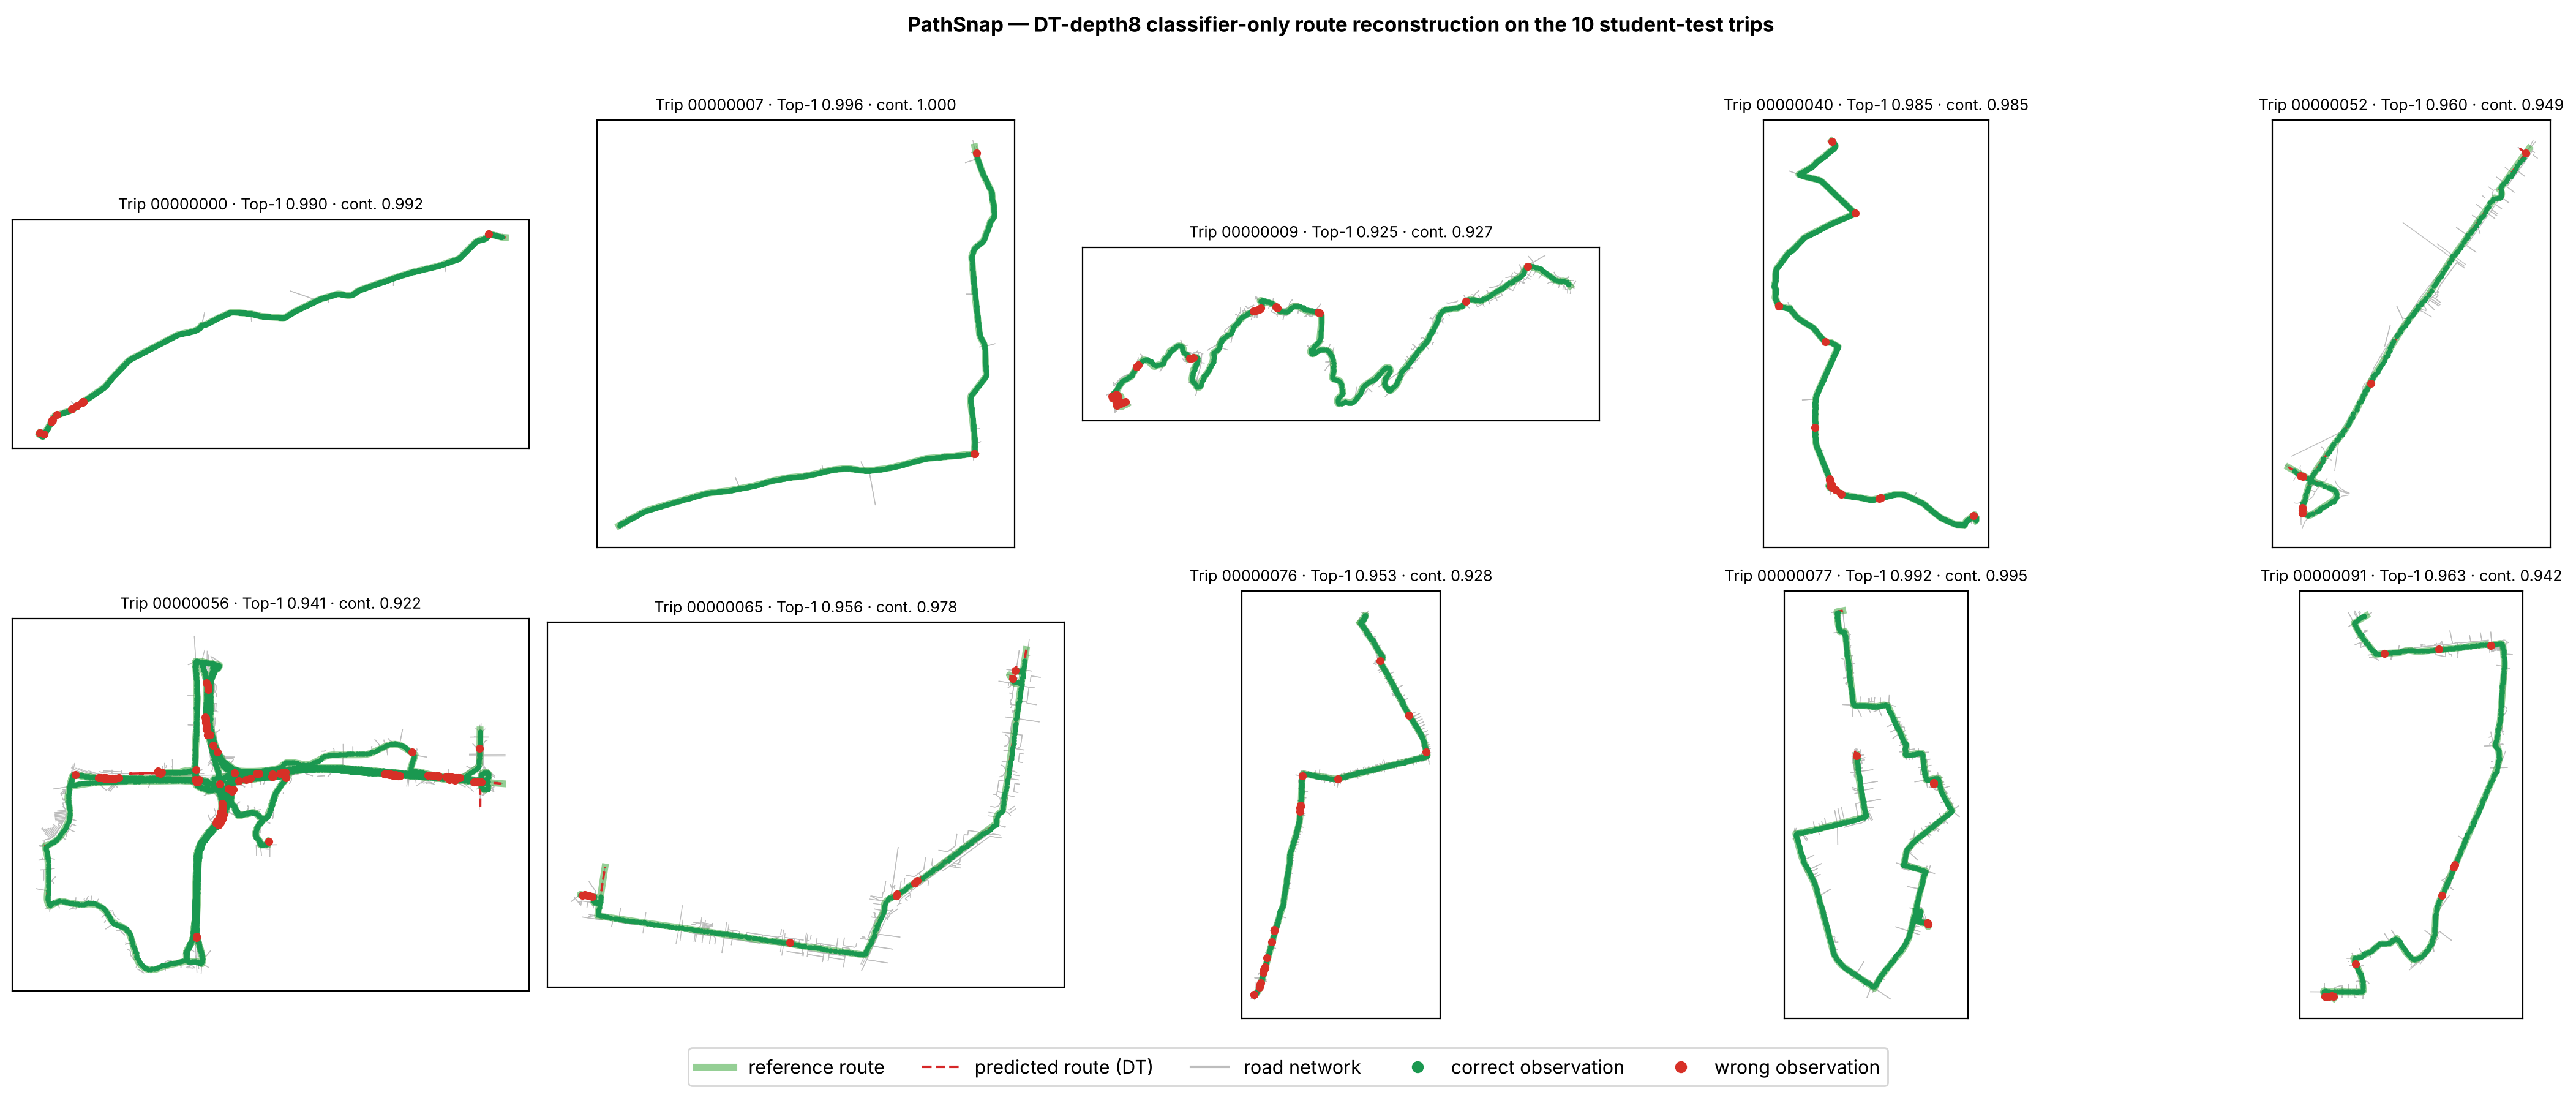

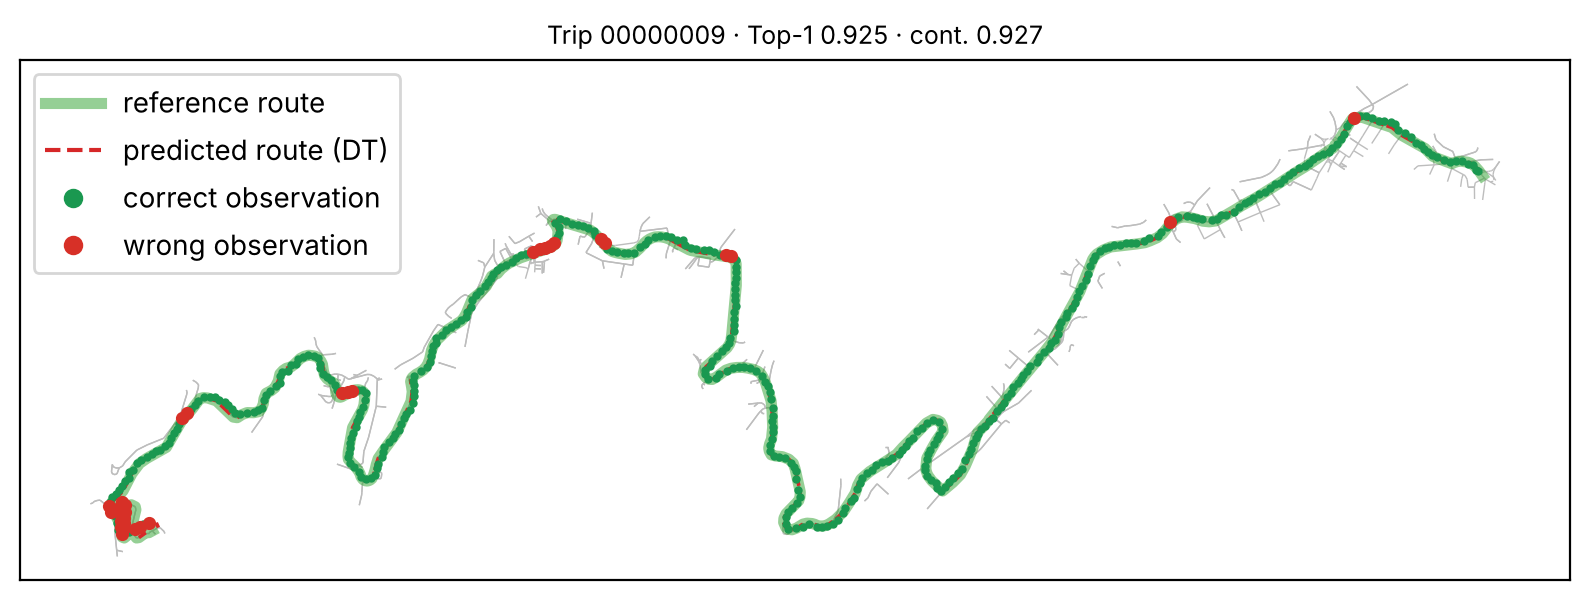

In [6]:
def static_map(tid, ax):
    z = NETS[tid]; g = pred[pred.trip == tid].sort_values("pt")
    route = pd.read_csv(os.path.join(DATA_DIR, "labels", "student_test", tid, "route_clean.csv"))
    sc = np.cos(np.radians(g.lat.mean()))
    from matplotlib.collections import LineCollection
    ax.add_collection(LineCollection([[(lo, la) for la, lo in arc_line(z, a)] for a in nearby_arcs(z, g)],
                                     colors="#bdbdbd", linewidths=0.5, zorder=1))
    for line in chain(z, route.canonical_arc_id.values):
        la, lo = zip(*line); ax.plot(lo, la, c="#2ca02c", lw=4, alpha=0.5, zorder=2)
    pa = g.pred_arc[g.pred_arc >= 0].values; pa = pa[np.r_[True, pa[1:] != pa[:-1]]]
    for line in chain(z, pa):
        la, lo = zip(*line); ax.plot(lo, la, c="#d62728", lw=1.3, ls="--", zorder=3)
    ok = g.labelled & (g.pred_arc == g.true_arc); bad = g.labelled & (g.pred_arc != g.true_arc)
    ax.scatter(g.lon[ok], g.lat[ok], s=4, c="#1a9850", zorder=4)
    ax.scatter(g.lon[bad], g.lat[bad], s=14, c="#d73027", zorder=5)
    ax.set_aspect(1 / sc); ax.set_xticks([]); ax.set_yticks([])
    t = per_trip.loc[tid]
    ax.set_title(f"Trip {tid} · Top-1 {t.top1_accuracy:.3f} · cont. {t.route_continuity:.3f}", fontsize=9)

from matplotlib.lines import Line2D
fig, axes = plt.subplots(2, 5, figsize=(22, 9))
for ax, tid in zip(axes.ravel(), per_trip.index.drop("ALL (pooled)")):
    static_map(tid, ax)
fig.legend(handles=[Line2D([], [], c="#2ca02c", lw=4, alpha=.5, label="reference route"),
                    Line2D([], [], c="#d62728", ls="--", label="predicted route (DT)"),
                    Line2D([], [], c="#bdbdbd", label="road network"),
                    Line2D([], [], marker="o", ls="", c="#1a9850", label="correct observation"),
                    Line2D([], [], marker="o", ls="", c="#d73027", label="wrong observation")],
           loc="lower center", ncol=5, fontsize=11)
fig.suptitle(f"PathSnap — {SEL} classifier-only route reconstruction on the 10 student-test trips", weight="bold")
plt.tight_layout(rect=(0, 0.05, 1, 0.96))
plt.savefig(os.path.join(OUT_DIR, "FINAL_static_maps_all_trips.png"), dpi=150); plt.show()

fig, ax = plt.subplots(figsize=(10, 9)); static_map(SHOW_TRIP, ax)
ax.legend(handles=[
    Line2D([], [], c="#2ca02c", lw=4, alpha=.5, label="reference route"),
    Line2D([], [], c="#d62728", ls="--", label="predicted route (DT)"),
    Line2D([], [], marker="o", ls="", c="#1a9850", label="correct observation"),
    Line2D([], [], marker="o", ls="", c="#d73027", label="wrong observation")], loc="best")
plt.savefig(os.path.join(OUT_DIR, f"FINAL_static_map_trip_{SHOW_TRIP}.png"), dpi=150, bbox_inches="tight"); plt.show()

## 10. Standard classification performance metrics (Decision Tree, depth 8)
Task the tree solves: for every (GPS point, candidate arc) row, predict **1 = this is the true arc**
or **0 = not the true arc** (threshold 0.5). Below: Accuracy, Precision, Recall, F1 per class,
their macro/weighted averages, ROC-AUC and the confusion matrix — on the training data and on the
10 student-test trips. The last row block is the route-level view: picking the top candidate per GPS point.

In [1]:
import os, joblib, numpy as np, pandas as pd, matplotlib.pyplot as plt
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score, roc_auc_score,
                             log_loss, confusion_matrix, classification_report, ConfusionMatrixDisplay)
OUT_DIR = "outputs/decision_tree"
bundle = joblib.load(os.path.join(OUT_DIR, "decision_tree.joblib"))
dt, FEATS = bundle["model"], bundle["features"]
C = pd.read_parquet("outputs/candidates.parquet")
tr = C[(C.part == "train") & C.use_for_tuning & C.labelled_pt]
te = C[(C.part == "student_test") & C.labelled_pt]

def clf_metrics(df, name):
    p = dt.predict_proba(df[FEATS])[:, 1]; y = df["label"].values; yh = (p >= 0.5).astype(int)
    tn, fp, fn, tp = confusion_matrix(y, yh).ravel()
    return {"Dataset": name, "Rows": len(y),
            "Accuracy": accuracy_score(y, yh),
            "Precision (true arc)": precision_score(y, yh), "Recall (true arc)": recall_score(y, yh),
            "F1 (true arc)": f1_score(y, yh),
            "Precision (not true arc)": precision_score(y, yh, pos_label=0),
            "Recall (not true arc)": recall_score(y, yh, pos_label=0),
            "F1 (not true arc)": f1_score(y, yh, pos_label=0),
            "Macro F1": f1_score(y, yh, average="macro"), "Weighted F1": f1_score(y, yh, average="weighted"),
            "ROC-AUC": roc_auc_score(y, p), "Log loss": log_loss(y, np.clip(p, 1e-15, 1 - 1e-15)),
            "TP": tp, "FP": fp, "FN": fn, "TN": tn}, y, yh

m_tr, _, _ = clf_metrics(tr, "Train (76 trips)")
m_te, y_te, yh_te = clf_metrics(te, "Student-test (10 trips)")
perf = pd.DataFrame([m_tr, m_te]).set_index("Dataset").T
perf.to_csv(os.path.join(OUT_DIR, "FINAL_classification_metrics.csv"))
perf

Dataset,Train (76 trips),Student-test (10 trips)
Rows,578536.000000,73886.000000
Accuracy,0.991676,0.990188
Precision (true arc),0.958871,0.940691
Recall (true arc),0.972628,0.976545
F1 (true arc),0.965700,0.958283
Precision (not true arc),0.996243,0.996925
Recall (not true arc),0.994285,0.991967
F1 (not true arc),0.995263,0.994440
Macro F1,0.980482,0.976361
Weighted F1,0.991701,0.990267


In [2]:
print("Classification report — student-test, candidate level (threshold 0.5)\n")
print(classification_report(y_te, yh_te, target_names=["not true arc (0)", "true arc (1)"], digits=4))

Classification report — student-test, candidate level (threshold 0.5)

                  precision    recall  f1-score   support

not true arc (0)     0.9969    0.9920    0.9944     65359
    true arc (1)     0.9407    0.9765    0.9583      8527

        accuracy                         0.9902     73886
       macro avg     0.9688    0.9843    0.9764     73886
    weighted avg     0.9904    0.9902    0.9903     73886



### Route-level performance (what matters for map matching)
For each GPS point, the candidate with the highest probability is the predicted road segment.
**Accuracy** here = share of GPS points matched to the correct road segment.

In [3]:
P = pd.read_csv(os.path.join(OUT_DIR, "FINAL_per_trip_metrics.csv"), dtype={"trip": str}).set_index("trip")
route_level = pd.DataFrame({
    "GPS points evaluated": [int(P.loc["ALL (pooled)", "labelled_obs"])],
    "Correctly matched": [int(P.loc["ALL (pooled)", "labelled_obs"] - P.loc["ALL (pooled)", "wrong_obs"])],
    "Wrongly matched": [int(P.loc["ALL (pooled)", "wrong_obs"])],
    "Matching accuracy": [P.loc["ALL (pooled)", "top1_accuracy"]],
    "Macro F1 over road segments": [P.loc["ALL (pooled)", "obs_macro_f1"]],
    "Route continuity": [P.loc["ALL (pooled)", "route_continuity"]]}, index=["Student-test"]).T
route_level

,Student-test
GPS points evaluated,8527.0000
Correctly matched,8263.0000
Wrongly matched,264.0000
Matching accuracy,0.9690
Macro F1 over road segments,0.9070
Route continuity,0.9635


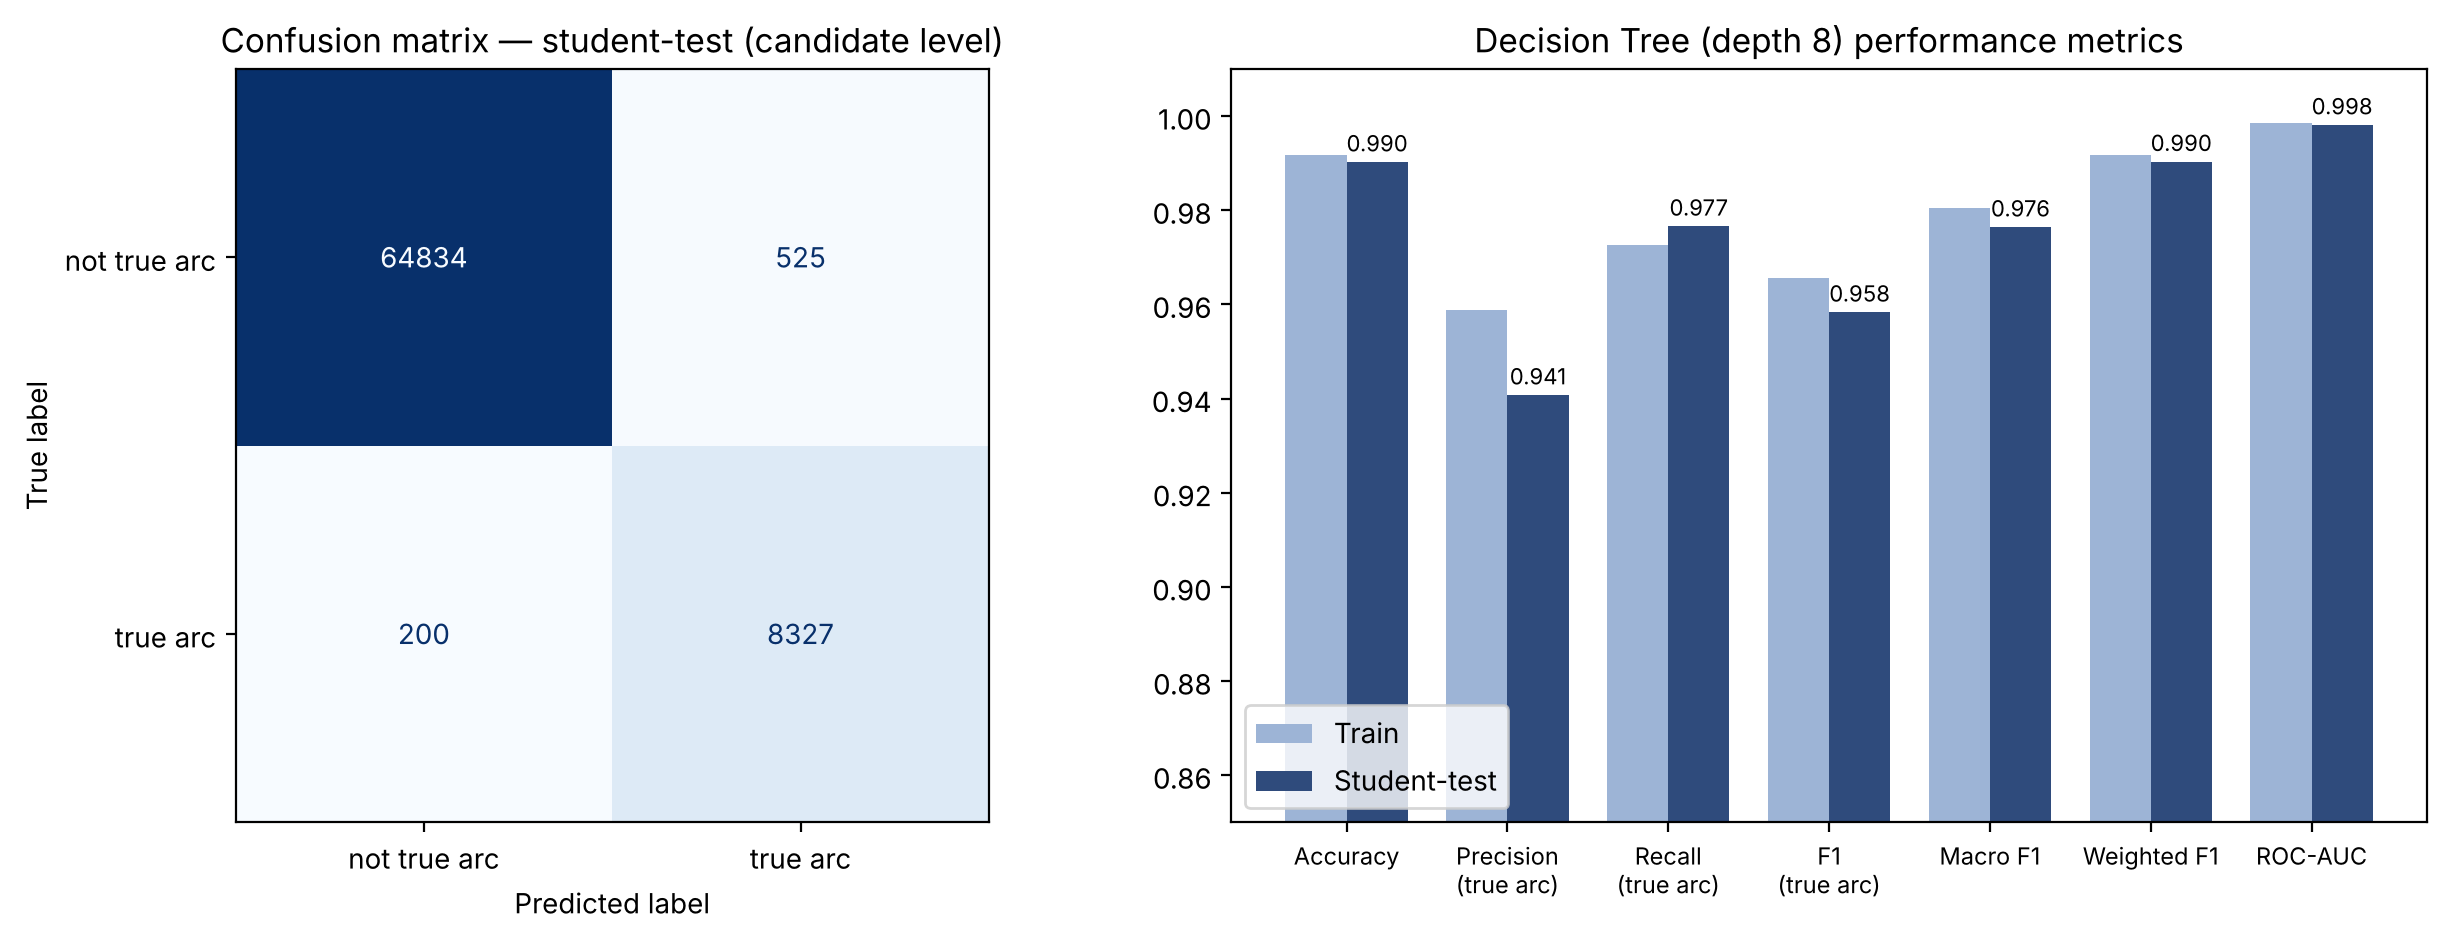

In [4]:
fig, ax = plt.subplots(1, 2, figsize=(13, 4.8))
ConfusionMatrixDisplay(confusion_matrix(y_te, yh_te), display_labels=["not true arc", "true arc"]).plot(
    ax=ax[0], colorbar=False, values_format="d", cmap="Blues")
ax[0].set_title("Confusion matrix — student-test (candidate level)")
keys = ["Accuracy", "Precision (true arc)", "Recall (true arc)", "F1 (true arc)", "Macro F1", "Weighted F1", "ROC-AUC"]
x = np.arange(len(keys)); w = 0.38
ax[1].bar(x - w / 2, [m_tr[k] for k in keys], w, label="Train", color="#9db4d6")
b = ax[1].bar(x + w / 2, [m_te[k] for k in keys], w, label="Student-test", color="#2f4b7c")
ax[1].bar_label(b, fmt="%.3f", fontsize=8, padding=2)
ax[1].set_xticks(x, [k.replace(" (true arc)", "\n(true arc)") for k in keys], fontsize=8.5)
ax[1].set_ylim(0.85, 1.01); ax[1].set_title("Decision Tree (depth 8) performance metrics"); ax[1].legend(loc="lower left")
plt.tight_layout(); plt.savefig(os.path.join(OUT_DIR, "FINAL_classification_metrics.png"), dpi=150); plt.show()